In [1]:
from astropy.io import fits
from astropy.wcs import WCS
import astropy
from astropy.coordinates import SkyCoord 
from astropy.wcs.utils import skycoord_to_pixel
from astropy.wcs.utils import pixel_to_skycoord
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

from os import listdir
from os.path import isfile, join
from datetime import datetime
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore', category=UserWarning, append=True)
warnings.filterwarnings("ignore", category=astropy.wcs.FITSFixedWarning)

In [2]:
def read_file(filename):
    hdu = fits.open(filename)[0]
    #Convert to 32bit int
    data = hdu.data.astype(int)
    #Try and reverse the overflow for values less than -1000
    data[data < -1e3] = ((2**15-1)-np.abs(data[data < -1e3])) + (2**15-1)
    return data, hdu.header

def centroid(image):
    
    xvals = np.arange(image.shape[1]) - image.shape[1]//2
    centroid_x = np.sum(xvals*image**2)/np.sum(image**2)
    centroid_y = np.sum(xvals*image.T**2)/np.sum(image**2)
    
    return np.array([centroid_y, centroid_x])

def get_aperture(image_shape, radius):
    
    aperture = np.zeros(image_shape)
    center = image_shape[0]//2, image_shape[1]//2
    for i in range(image_shape[0]):
        for j in range(image_shape[1]):
            dist = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if dist < radius: 
                aperture[j,i] = 1
    return aperture

def get_annulus(image_shape, radius_inner, radius_outer):
    
    annulus = np.zeros(image_shape)
    center = image_shape[0]//2, image_shape[1]//2
    for i in range(image_shape[0]):
        for j in range(image_shape[1]):
            dist = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if dist > radius_inner and  dist < radius_outer: 
                annulus[j,i] = 1
    return annulus

In [3]:
#get all of the files 
img_files = [f for f in listdir('.') if isfile(join('.', f)) and 'fits' in f]

print(img_files)

file_times = []
for f in img_files:
    header = fits.open(f)[0].header
    dt = datetime.fromisoformat(header["DATE-OBS"])
    file_times.append(dt)

#sort files by the same way
file_times, img_files = zip(*sorted(zip(file_times, img_files)))

img_files = np.array(img_files)
file_times = np.array(file_times)

['AST325-326-SN-20151004.3792.fits', 'AST325-326-SN-20151008.9958.fits', 'AST325-326-SN-20151026.0264.fits', 'AST325-326-SN-20151008.5583.fits', 'AST325-326-SN-20151012.1208.fits', 'AST325-326-SN-20151009.0868.fits', 'AST325-326-SN-20151012.1375.fits', 'AST325-326-SN-20151027.1743.fits', 'AST325-326-SN-20151004.6354.fits', 'AST325-326-SN-20150928.1257.fits', 'AST325-326-SN-20151029.2604.fits', 'AST325-326-SN-20150922.6569.fits', 'AST325-326-SN-20151002.6236.fits', 'AST325-326-SN-20151008.3743.fits', 'AST325-326-SN-20150930.3778.fits', 'AST325-326-SN-20151004.3243.fits', 'AST325-326-SN-20150922.2410.fits', 'AST325-326-SN-20151029.2764.fits', 'AST325-326-SN-20151027.0896.fits', 'AST325-326-SN-20151009.0722.fits', 'AST325-326-SN-20150928.6514.fits', 'AST325-326-SN-20151029.1826.fits', 'AST325-326-SN-20151008.5403.fits', 'AST325-326-SN-20151008.1528.fits', 'AST325-326-SN-20151019.5396.fits', 'AST325-326-SN-20150922.2083.fits', 'AST325-326-SN-20151024.4271.fits', 'AST325-326-SN-20151006.169

In [4]:
#Find best aperture annulus
f = img_files[0]

readout_noise = 10
# read the image
data, header  = read_file(f)

boxsize = 70

# locate the star
w = WCS(header)
ref_pos = skycoord_to_pixel(ref_b, w)
ref_x, ref_y = ref_pos
ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)

#generate region around star and get local centroid
sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, ref_x_int-boxsize: ref_x_int+boxsize+1]
cent = np.round(centroid(sub_im),0).astype(int)

#Round to nearest integer, adjust by a few pixels if needed
ref_x_int += cent[1]
ref_y_int += cent[0]

#Generate a new region with a better center
sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
              ref_x_int-boxsize: ref_x_int+boxsize+1]

#Compute fixed annulus 
annulus = get_annulus(sub_im.shape, 30, 50)

#Background 
bg = np.sum(sub_im*annulus)/annulus[annulus>0].size
#         plt.imshow(sub_im*annulus)
#         plt.show()
        #Compute flux
    
def gaus(x,a,x0,sigma):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))

from scipy.optimize import curve_fit
popt,pcov = curve_fit(gaus,np.arange(sub_im.shape[1]),sub_im[sub_im.shape[0]//2,:],p0=[1,70,5])
        
plt.plot(sub_im[sub_im.shape[0]//2,:])
plt.plot(np.arange(sub_im.shape[1]),gaus(np.arange(sub_im.shape[1]),*popt),color = 'r')
plt.show()
print(popt)
#Radii to try
trial_radii = np.linspace(2, 30)

SNRs = np.empty_like(trial_radii)

for i, radii in enumerate(trial_radii):
    
    #Get aperture
    aperture = get_aperture(sub_im.shape, radii)
    
    #Compute flux
    flux = np.sum((sub_im- bg)*aperture )
    
    #pixs in aperture
    N = aperture[aperture > 0].size
    noise = np.sqrt(flux + (1/64)*(N*bg + readout_noise))
    
    SNRs[i] = flux/noise

NameError: name 'ref_b' is not defined

In [ ]:
plt.plot(trial_radii, SNRs)
plt.show()

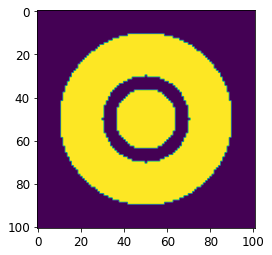

2015-09-20T22:02:14 442.6309904153355 0.11554845580404687 0.8423645320197044


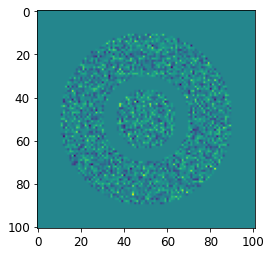

2015-09-20T22:28:10 -271.2875399361021 0.4536741214057508 0.008210180623973728


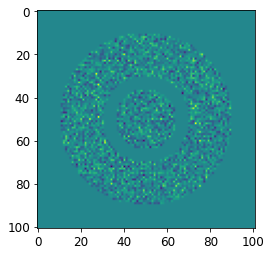

2015-09-20T22:53:57 -65.65015974440902 0.6480298189563365 0.5402298850574713


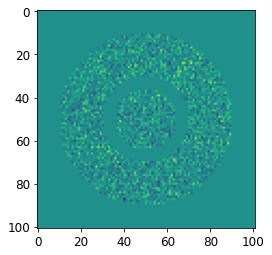

2015-09-22T03:30:17 43.07028753993614 0.8668796592119276 0.9376026272577996


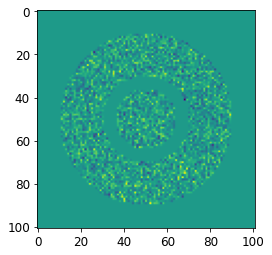

2015-09-22T03:53:05 -606.9392971246007 0.7486687965921193 -0.24794745484400657


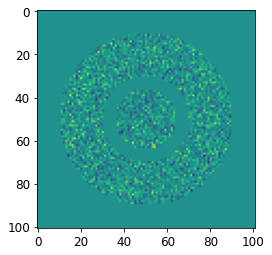

2015-09-22T04:13:38 -250.9648562300319 0.7667731629392971 0.35467980295566504


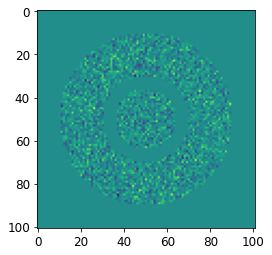

2015-09-22T04:37:45 122.63258785942472 0.13525026624068157 0.3366174055829228


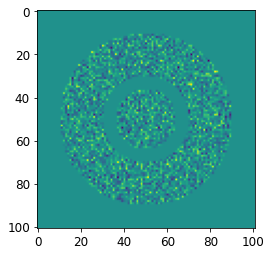

2015-09-22T05:00:06 -142.15095846645363 0.13817891373801916 -0.09523809523809523


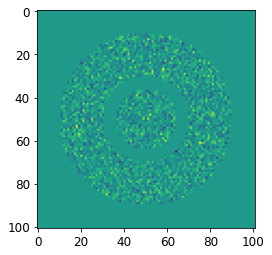

2015-09-22T05:23:39 -163.6677316293933 0.43130990415335463 0.1625615763546798


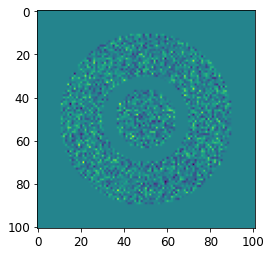

2015-09-22T05:47:05 39.29472843450478 0.3016506922257721 0.36617405582922824


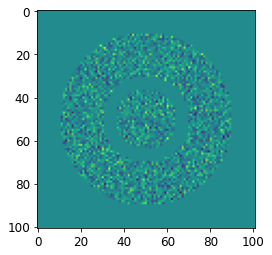

2015-09-22T06:10:07 -494.92651757188503 1.5729499467518637 0.7602627257799671


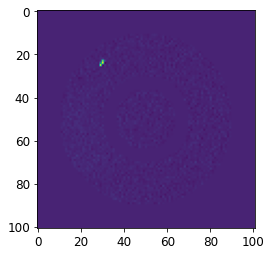

2015-09-22T06:34:25 -597.5311501597441 0.7824813631522897 -0.1986863711001642


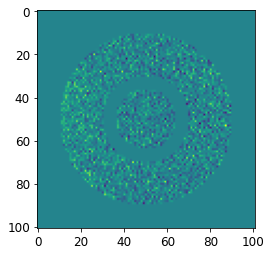

2015-09-22T06:56:08 -210.8450479233229 0.5777422790202343 0.2315270935960591


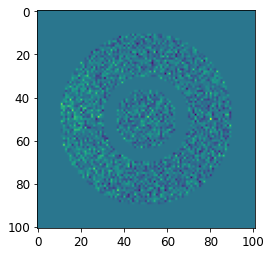

2015-09-22T13:04:07 398.84824281150156 -0.2050053248136315 0.44991789819376027


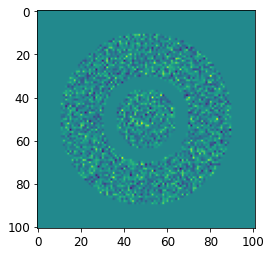

2015-09-22T13:27:50 -12.817092651757342 0.2558572949946752 0.2348111658456486


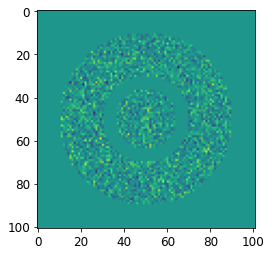

2015-09-22T13:52:59 679.5335463258783 0.9137380191693291 2.0295566502463056


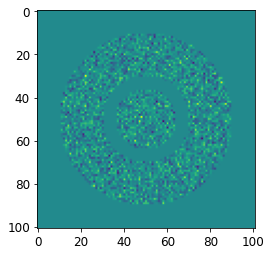

2015-09-22T14:26:03 -207.12619808306675 0.4435569755058573 0.10344827586206896


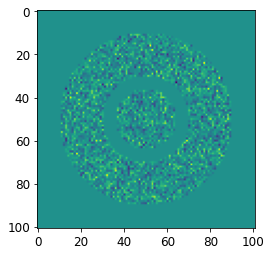

2015-09-22T14:58:13 169.75559105431304 -0.01437699680511182 0.26436781609195403


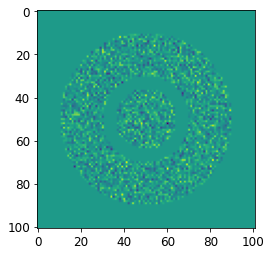

2015-09-22T15:23:34 -38.95607028753987 0.5417997870074548 0.47783251231527096


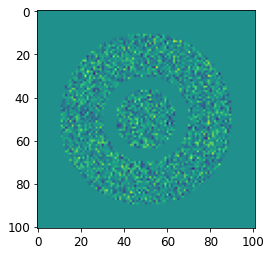

2015-09-22T15:46:09 33.44408945686913 0.47710330138445156 0.5320197044334976


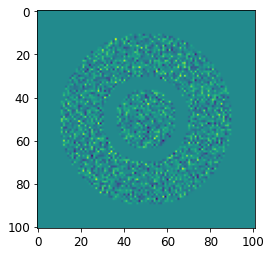

2015-09-22T16:13:14 -11.342651757188632 0.4406283280085197 0.4220032840722496


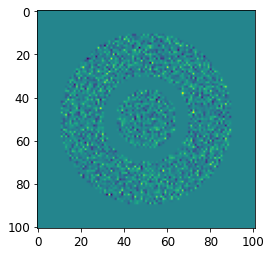

2015-09-22T16:40:33 -2.404153354632612 0.6821086261980831 0.6781609195402298


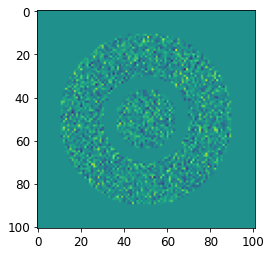

2015-09-22T18:32:01 175.26757188498402 0.30005324813631523 0.5878489326765188


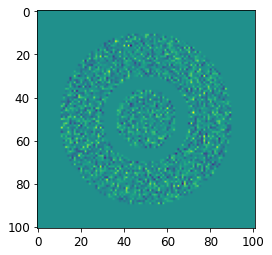

2015-09-24T12:59:29 67.53434504792324 -1.0764110756123535 -0.9655172413793104


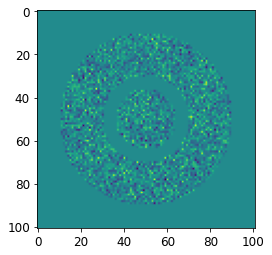

2015-09-24T13:28:52 142.04472843450486 -0.7816826411075612 -0.548440065681445


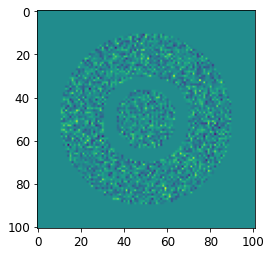

2015-09-24T13:56:46 166.6341853035145 -0.17838125665601703 0.09523809523809523


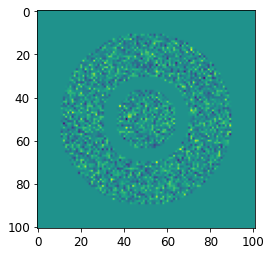

2015-09-24T14:22:30 421.21006389776375 -0.7425452609158679 -0.05090311986863711


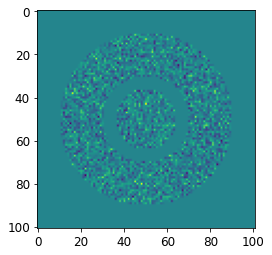

2015-09-24T17:55:11 59.677316293929714 0.02023429179978701 0.11822660098522167


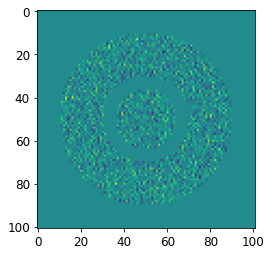

2015-09-24T21:33:29 493.62619808306664 -0.9435569755058573 -0.1330049261083744


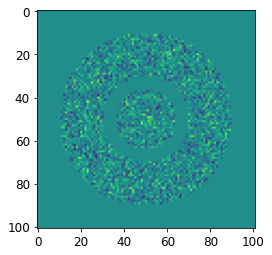

2015-09-24T21:56:43 59.62060702875455 -1.0125133120340788 -0.9146141215106732


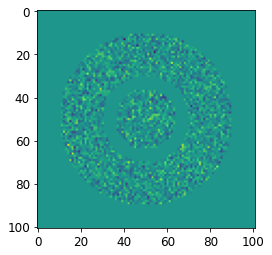

2015-09-24T22:21:03 825.4720447284349 -1.178115015974441 0.17733990147783252


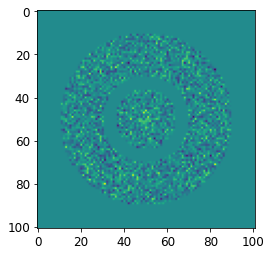

2015-09-24T22:46:26 634.1813099041533 -1.0971778487752928 -0.05582922824302135


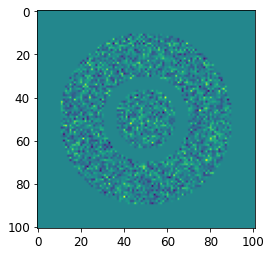

2015-09-24T23:11:04 488.01757188498414 -0.7832800851970181 0.0180623973727422


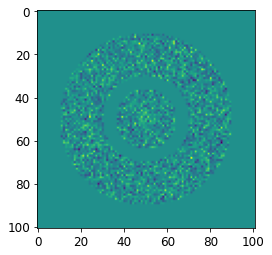

2015-09-24T23:34:45 -115.95527156549463 -0.4483493077742279 -0.638752052545156


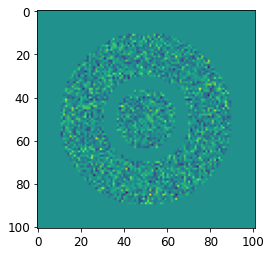

2015-09-24T23:57:29 305.0439297124597 -0.45820021299254526 0.042692939244663386


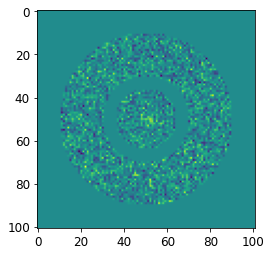

2015-09-25T00:20:00 770.380990415335 -0.3011182108626198 0.9638752052545156


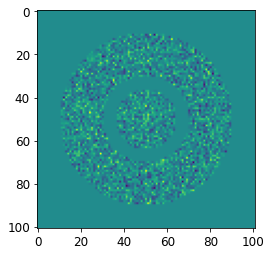

2015-09-25T00:41:33 -178.30111821086257 0.619542066027689 0.32676518883415434


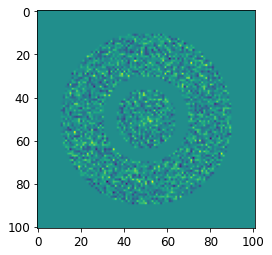

2015-09-25T01:08:02 545.4904153354637 -0.284877529286475 0.6108374384236454


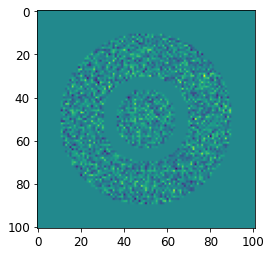

2015-09-25T01:34:03 568.035143769968 0.10010649627263046 1.0328407224958949


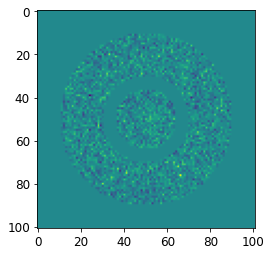

2015-09-25T01:58:49 469.3666134185304 0.5215654952076677 1.2922824302134648


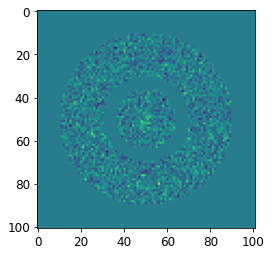

2015-09-25T02:20:18 458.0623003194886 0.43503727369542067 1.187192118226601


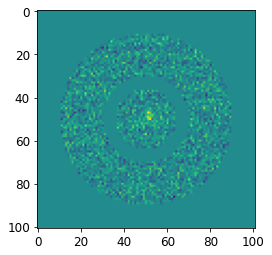

2015-09-25T02:41:48 534.1789137380191 0.2066027689030884 1.083743842364532


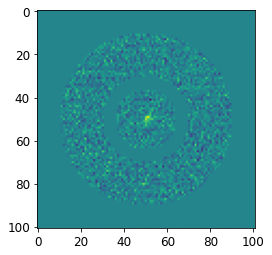

2015-09-25T03:02:42 369.5854632587857 0.22071352502662406 0.8275862068965517


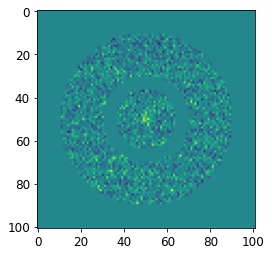

2015-09-26T12:52:44 -219.06070287539995 -3.415335463258786 -3.77504105090312


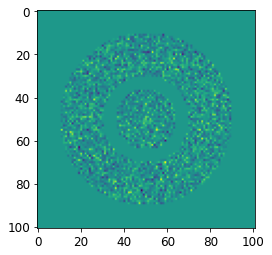

2015-09-26T13:17:55 255.32028753993626 -4.049787007454739 -3.6305418719211824


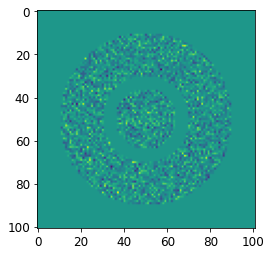

2015-09-26T13:41:58 589.0415335463247 -4.487752928647497 -3.5205254515599345


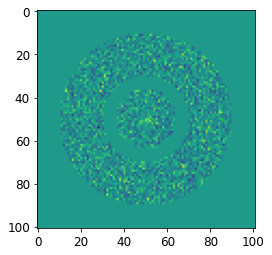

2015-09-26T14:16:40 627.1341853035146 -3.6783812566560172 -2.6486042692939247


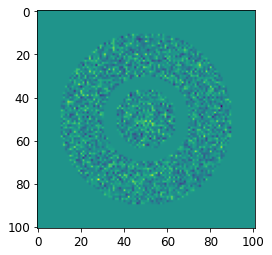

2015-09-26T14:42:01 -153.132587859426 -3.301916932907348 -3.5533661740558293


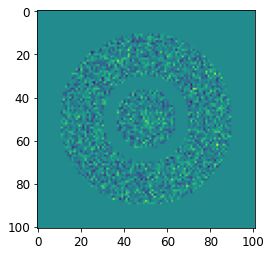

2015-09-26T15:07:44 -583.5934504792328 -3.3192225772097976 -4.277504105090312


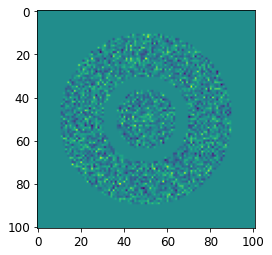

2015-09-26T15:32:11 -47.72124600638998 -2.2287007454739083 -2.3070607553366176


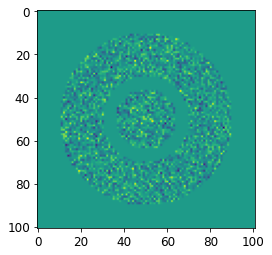

2015-09-26T15:34:38 1175.9912140575072 -3.108359957401491 -1.1773399014778325


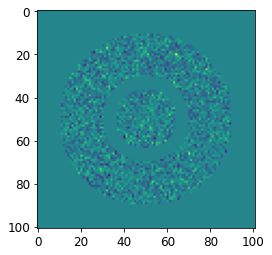

2015-09-26T16:07:08 -71.72364217252317 -2.9249201277955272 -3.0426929392446636


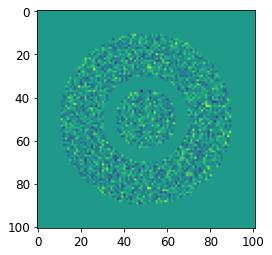

2015-09-26T16:30:50 630.7667731629392 -3.5431309904153356 -2.5073891625615765


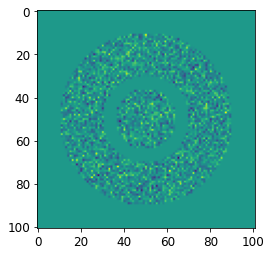

2015-09-26T17:01:46 320.5039936102232 -2.4507454739084134 -1.9244663382594418


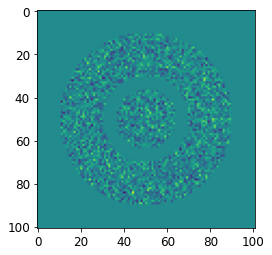

2015-09-26T17:41:14 348.8218849840257 -3.196751863684771 -2.6239737274220034


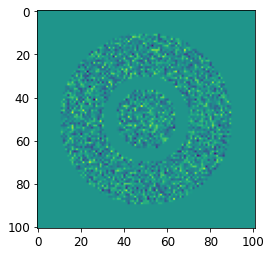

2015-09-26T18:09:09 1031.6126198083073 -2.777689030883919 -1.083743842364532


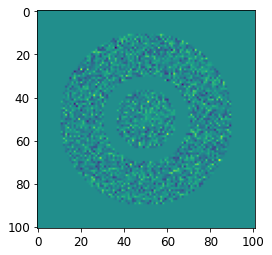

2015-09-28T03:01:00 1469.9968051118212 1.9605963791267305 4.374384236453202


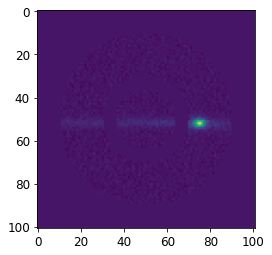

2015-09-28T03:03:05 1524.9193290734822 0.6717252396166135 3.1756978653530377


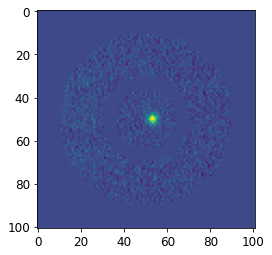

2015-09-28T03:24:54 1389.3785942492011 0.3359957401490948 2.6174055829228244


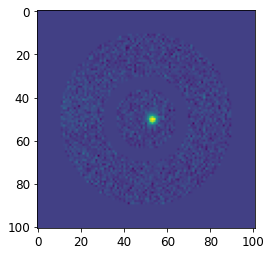

2015-09-28T03:46:43 -582.8186900958464 0.23615548455804047 -0.7208538587848933


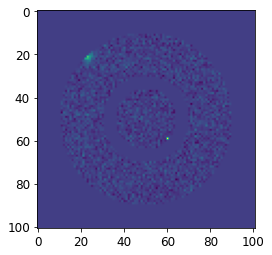

2015-09-28T04:07:34 1307.1477635782744 -0.8442492012779552 1.3021346469622332


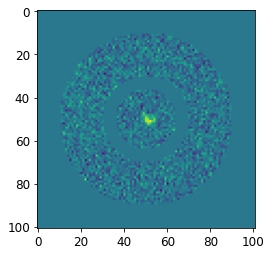

2015-09-28T04:28:06 -12.331469648562233 -3.7547923322683707 -3.77504105090312


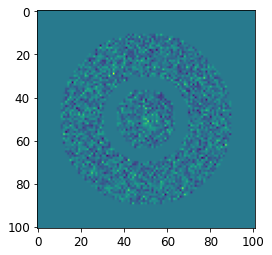

2015-09-28T04:50:13 536.5423322683711 -3.97790202342918 -3.09688013136289


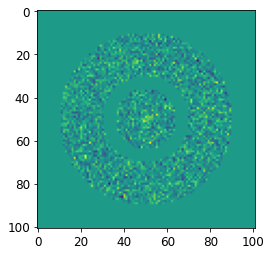

2015-09-28T05:19:44 665.1062300319497 -3.689829605963791 -2.5977011494252875


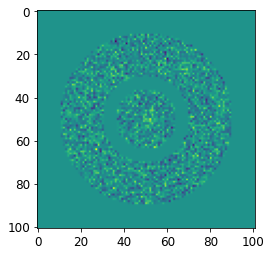

2015-09-28T05:44:10 3443.647763578275 -5.677582534611289 -0.022988505747126436


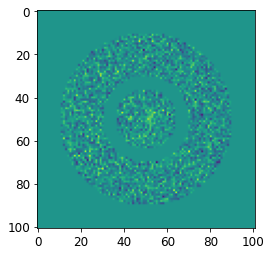

2015-09-28T06:06:12 2467.995207667731 -5.059105431309904 -1.006568144499179


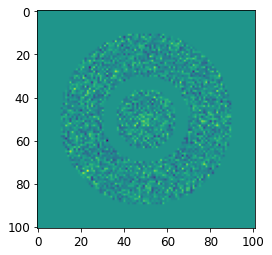

2015-09-28T06:28:49 1518.3370607028753 -3.176251331203408 -0.6830870279146142


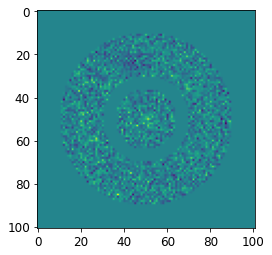

2015-09-28T06:50:10 -12.488817891374026 -2.362087326943557 -2.3825944170771756


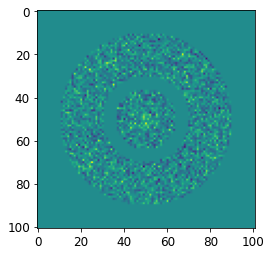

2015-09-28T07:14:26 -19.365814696486694 -2.8450479233226837 -2.876847290640394


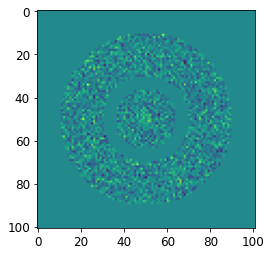

2015-09-28T07:35:50 1684.6845047923314 -4.22444089456869 -1.458128078817734


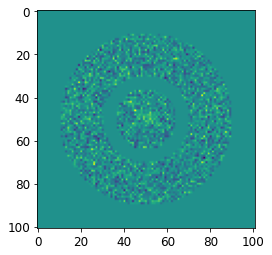

2015-09-28T08:00:13 881.5015974440898 -2.813631522896699 -1.3661740558292284


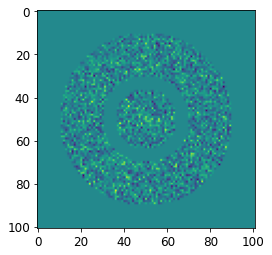

2015-09-28T08:23:04 1847.6230031948887 -2.982960596379127 0.05090311986863711


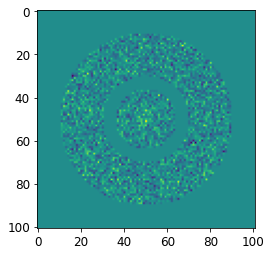

2015-09-28T08:43:29 1035.7691693290744 -2.8469116080937167 -1.1461412151067323


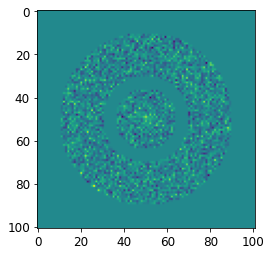

2015-09-28T09:11:01 1550.0247603833877 -3.3612886048988284 -0.8160919540229885


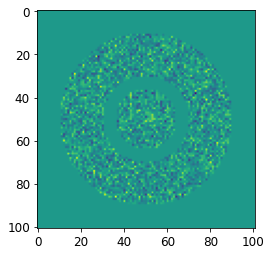

2015-09-28T12:48:03 1128.2515974440898 -11.5636315228967 -9.711001642036125


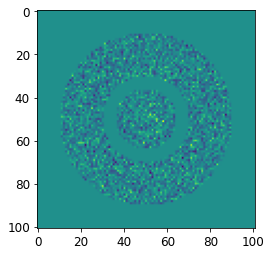

2015-09-28T13:17:19 1343.6453674121412 -9.70713525026624 -7.500821018062397


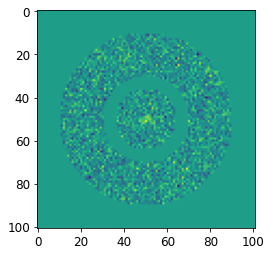

2015-09-28T13:42:52 1210.0095846645359 -11.215122470713524 -9.22824302134647


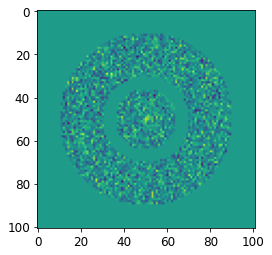

2015-09-28T14:10:57 1405.5455271565506 -10.605165069222577 -8.29720853858785


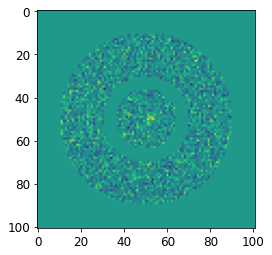

2015-09-28T14:41:15 1671.3993610223652 -9.741214057507987 -6.996715927750411


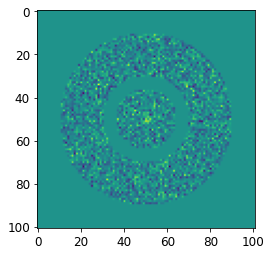

2015-09-28T15:09:50 3553.1853035143768 -11.047923322683706 -5.213464696223317


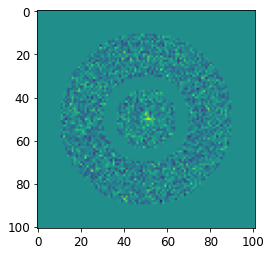

2015-09-28T15:38:02 2006.5734824281137 -10.593716719914802 -7.2988505747126435


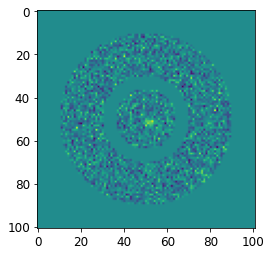

2015-09-28T16:07:12 599.9313099041515 -9.847177848775292 -8.862068965517242


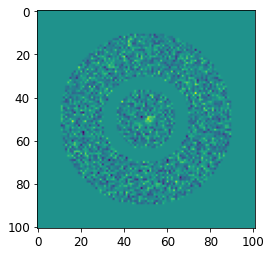

2015-09-28T16:34:35 230.6365814696482 -10.815495207667732 -10.436781609195402


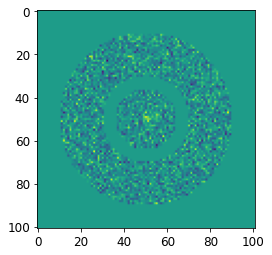

2015-09-28T16:57:56 1908.8170926517566 -11.922523961661343 -8.788177339901479


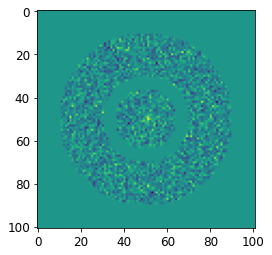

2015-09-28T17:27:57 277.6214057507973 -13.00266240681576 -12.54679802955665


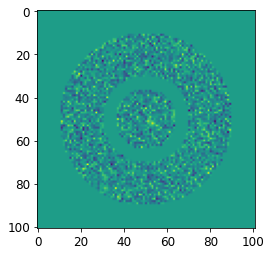

2015-09-28T17:54:44 3134.331469648562 -13.245207667731629 -8.098522167487685


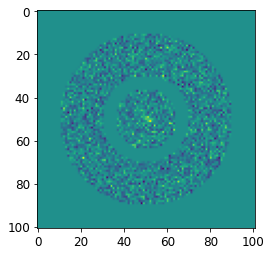

2015-09-30T08:00:55 3326.57268370607 -1.270234291799787 4.192118226600985


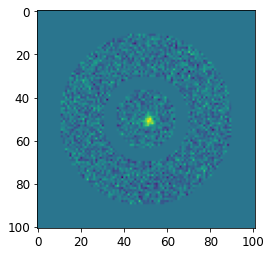

2015-09-30T08:22:24 2154.1861022364214 1.628594249201278 5.165845648604269


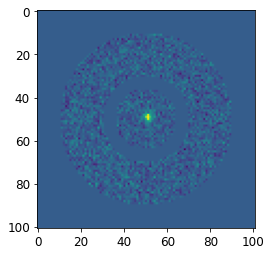

2015-09-30T08:44:35 3285.051916932907 1.9736421725239617 7.367816091954023


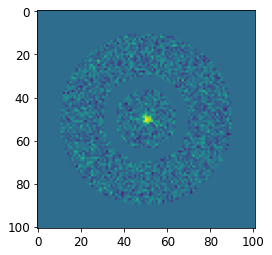

2015-09-30T09:04:28 2190.70127795527 -0.01757188498402556 3.5796387520525452


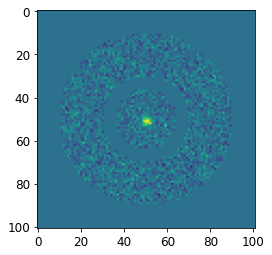

2015-09-30T13:16:05 2108.2468051118212 -0.9560702875399361 2.5057471264367814


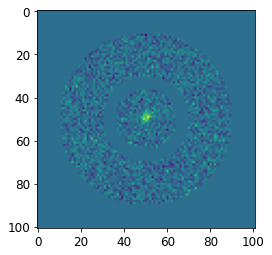

2015-09-30T13:40:58 941.8330670926512 7.274494142705005 8.821018062397373


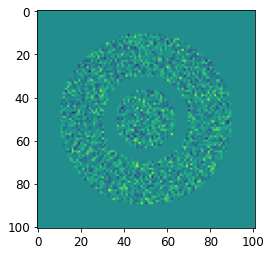

2015-09-30T15:38:23 1258.6517571884995 -15.961661341853036 -13.894909688013136


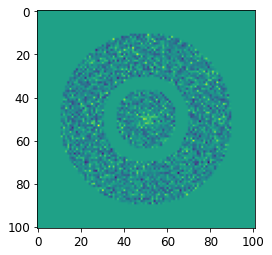

2015-09-30T16:04:06 -1105.875399361022 21.536741214057507 19.720853858784892


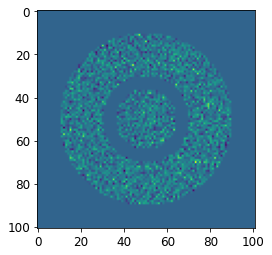

2015-09-30T16:30:53 1488.0734824281158 -2.4270500532481365 0.016420361247947456


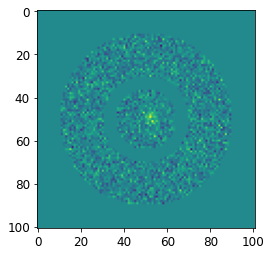

2015-09-30T16:53:28 2510.815495207668 -0.9422257720979765 3.180623973727422


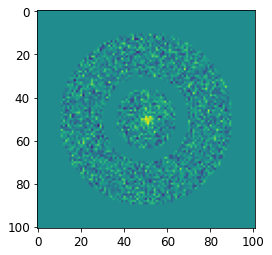

2015-09-30T17:21:01 2249.8514376996814 -2.4989350372736956 1.1954022988505748


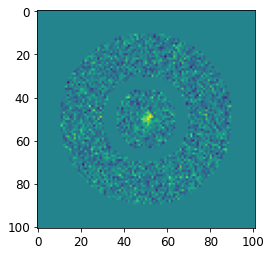

2015-09-30T17:47:58 2188.8714057507987 -3.2526624068157615 0.3415435139573071


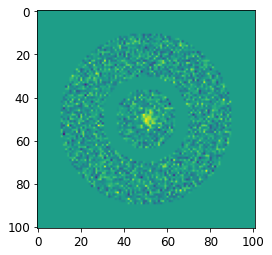

2015-09-30T18:15:29 2135.3354632587866 -3.862619808306709 -0.3563218390804598


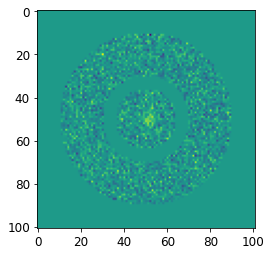

2015-10-02T02:59:16 1152.2859424920125 -0.4733759318423855 1.4187192118226601


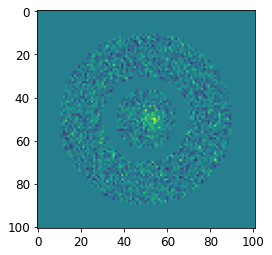

2015-10-02T03:23:03 1029.232428115016 -2.800053248136315 -1.110016420361248


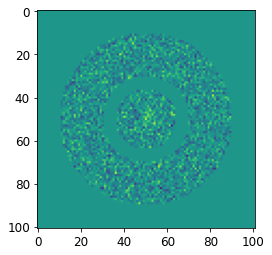

2015-10-02T03:44:10 3010.458466453674 -0.012247071352502662 4.931034482758621


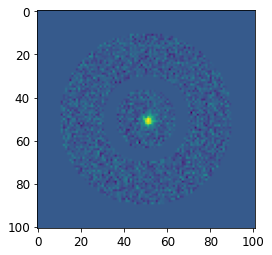

2015-10-02T04:10:51 3088.831469648562 -2.7452076677316293 2.3267651888341545


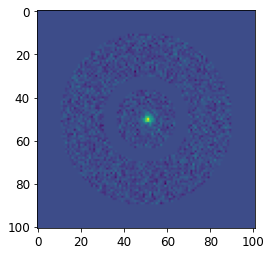

2015-10-02T04:34:23 4658.270766773162 0.006123535676251331 7.655172413793103


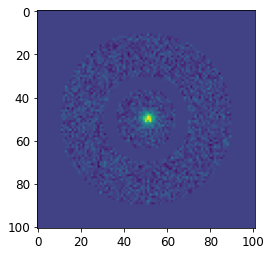

2015-10-02T05:00:26 4941.639776357828 -0.10942492012779553 8.004926108374384


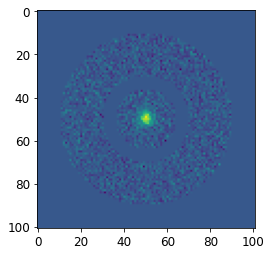

2015-10-02T05:32:19 4718.670127795527 -0.40175718849840253 7.346469622331691


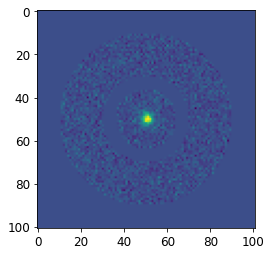

2015-10-02T05:53:28 4801.224440894568 -0.23189563365282215 7.651888341543514


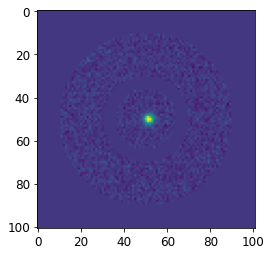

2015-10-02T06:14:13 4801.408146964855 -2.299520766773163 5.584564860426929


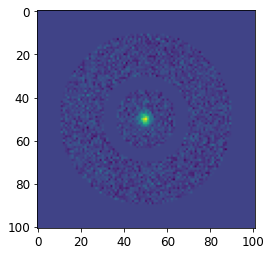

2015-10-02T06:35:32 4797.379392971245 0.012513312034078808 7.889983579638752


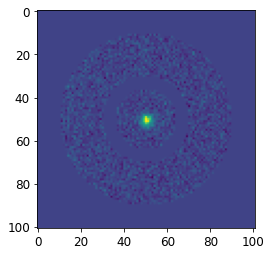

2015-10-02T06:57:38 4337.585463258786 -0.7792864749733759 6.343185550082102


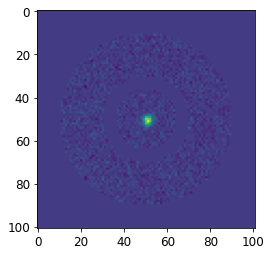

2015-10-02T07:17:52 4827.777955271565 -0.07188498402555911 7.855500821018063


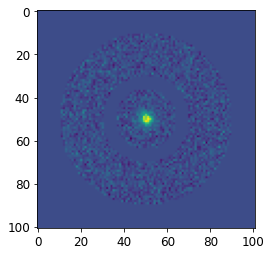

2015-10-02T07:40:48 4487.260383386581 -0.12193823216187434 7.246305418719212


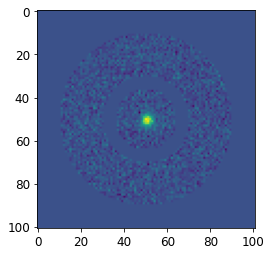

2015-10-02T08:02:11 4081.3202875399356 -0.04978700745473908 6.651888341543514


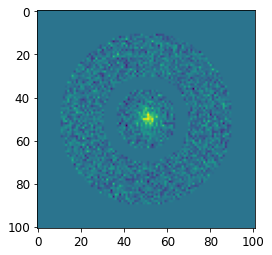

2015-10-02T08:21:12 4627.857028753994 -0.4299787007454739 7.169129720853859


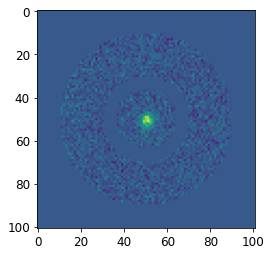

2015-10-02T08:43:08 3090.161341853036 0.3232161874334398 5.397372742200329


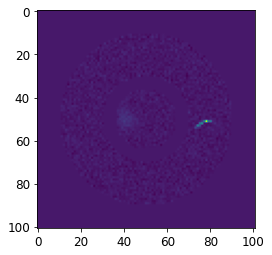

2015-10-02T09:00:52 5338.476837060702 -0.4523429179978701 8.313628899835797


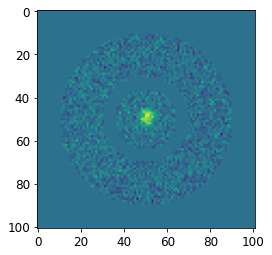

2015-10-02T12:18:17 2970.593450479233 0.31922257720979763 5.197044334975369


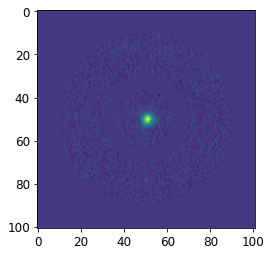

2015-10-02T12:42:38 3128.2979233226833 0.34105431309904155 5.477832512315271


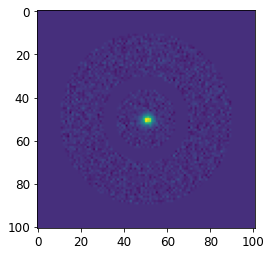

2015-10-02T13:05:27 3082.037539936102 0.12965921192758253 5.190476190476191


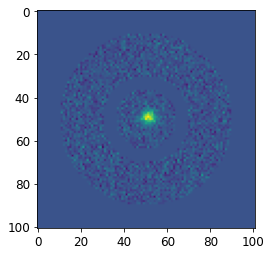

2015-10-02T13:33:09 3371.82428115016 -0.16719914802981894 5.369458128078818


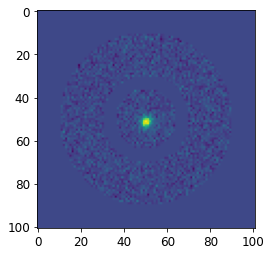

2015-10-02T14:05:22 3288.130990415336 -0.051118210862619806 5.348111658456486


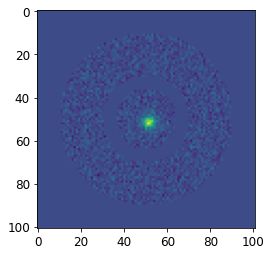

2015-10-02T14:31:15 3053.769968051118 -0.503727369542066 4.510673234811166


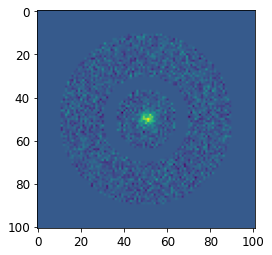

2015-10-02T14:58:12 3123.6086261980827 -0.4936102236421725 4.635467980295567


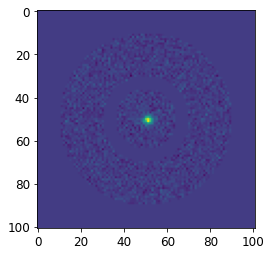

2015-10-02T15:27:20 3118.978434504792 -0.2659744408945687 4.855500821018063


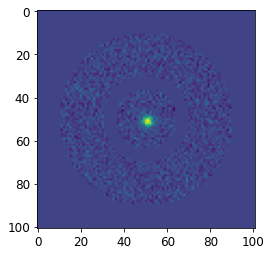

2015-10-02T16:01:30 2543.3410543130994 -0.4603301384451544 3.715927750410509


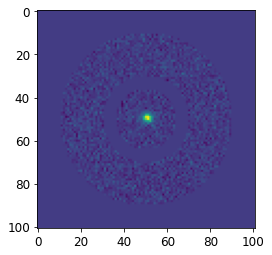

2015-10-02T16:28:13 3071.230031948882 -0.16293929712460065 4.880131362889983


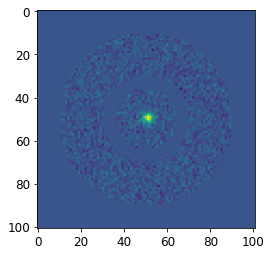

2015-10-02T16:50:20 3221.776357827476 -0.7582534611288605 4.532019704433497


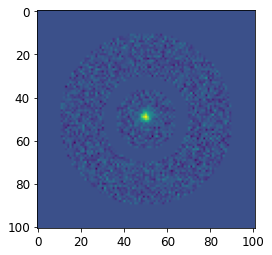

2015-10-02T17:43:01 2853.210063897763 -0.4092119275825346 4.275862068965517


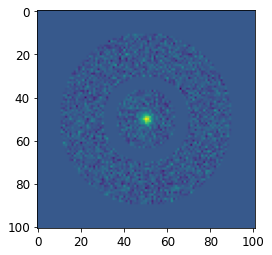

2015-10-02T18:01:48 2933.949680511183 -0.6206070287539937 4.197044334975369


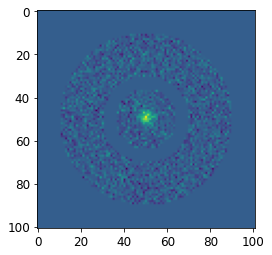

2015-10-04T02:36:43 3441.744408945687 0.1810436634717785 5.832512315270936


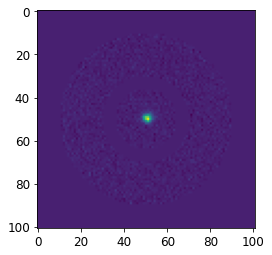

2015-10-04T02:58:26 3697.9017571884983 0.12167199148029818 6.19376026272578


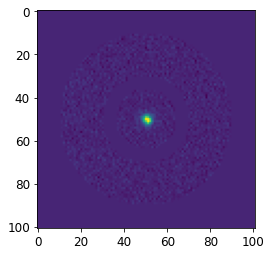

2015-10-04T03:20:59 4221.407348242812 0.023961661341853034 6.955665024630542


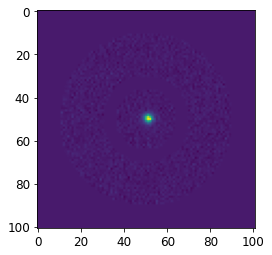

2015-10-04T03:43:40 2943.523162939297 -0.21432374866879658 4.619047619047619


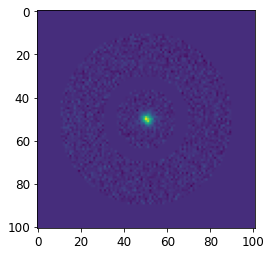

2015-10-04T04:06:57 3532.28194888179 -0.18929712460063897 5.610837438423645


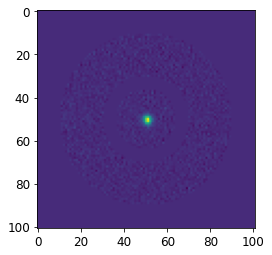

2015-10-04T04:30:05 3704.4784345047924 -0.43264110756123536 5.650246305418719


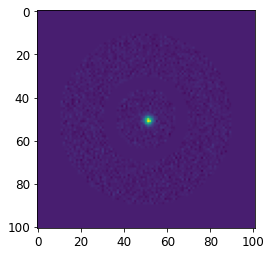

2015-10-04T04:58:05 3434.437699680511 0.06496272630457935 5.704433497536946


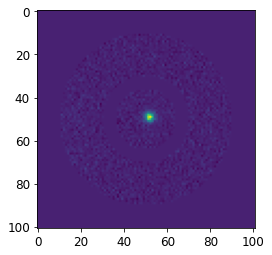

2015-10-04T05:22:24 2893.9392971246 -0.08200212992545261 4.669950738916256


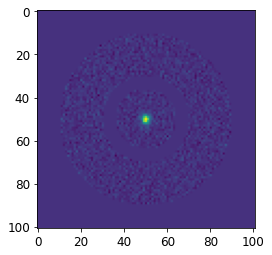

2015-10-04T05:42:43 3740.6285942492004 0.7526624068157615 6.894909688013136


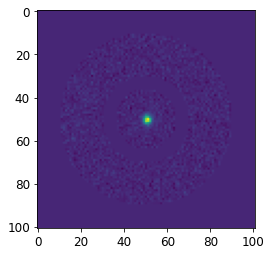

2015-10-04T06:02:55 2996.8043130990413 0.586528221512247 5.5073891625615765


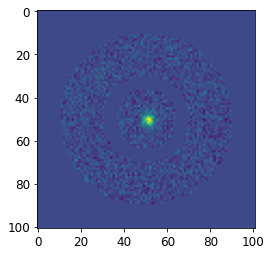

2015-10-04T06:23:18 3178.0351437699674 0.10010649627263046 5.318555008210181


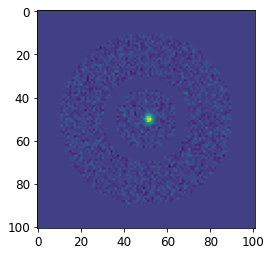

2015-10-04T06:44:13 2511.7675718849846 1.466719914802982 5.5911330049261085


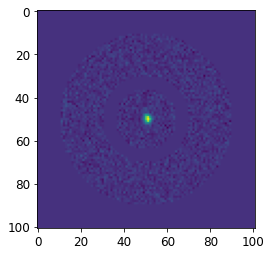

2015-10-04T07:04:00 3088.8442492012778 2.079073482428115 7.151067323481117


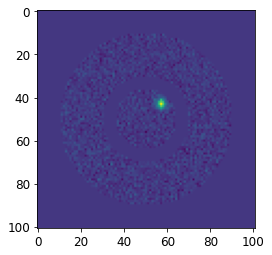

2015-10-04T07:24:34 4397.089456869009 -0.23003194888178913 6.990147783251231


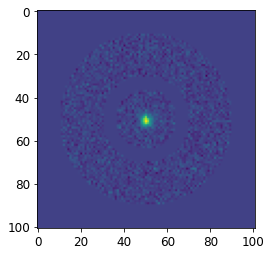

2015-10-04T07:47:15 3473.2332268370606 0.8764643237486688 6.579638752052545


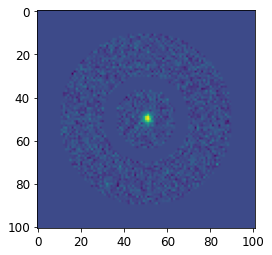

2015-10-04T08:09:10 3579.4840255591057 1.3029818956336527 7.180623973727422


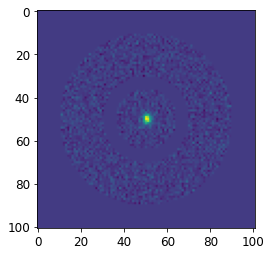

2015-10-04T08:29:49 3826.329872204473 0.7350905218317358 7.018062397372742


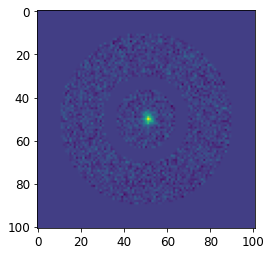

2015-10-04T08:51:18 4736.9177316293935 0.9853567625133121 8.763546798029557


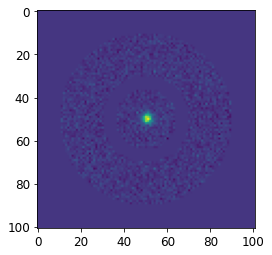

2015-10-04T09:06:13 3424.757987220447 0.3485090521831736 5.972085385878489


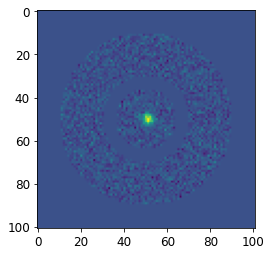

2015-10-04T12:15:18 4105.269169329074 0.31975505857294995 7.060755336617405


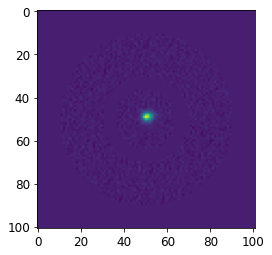

2015-10-04T12:37:53 17427.585463258783 0.8873801916932907 29.504105090311988


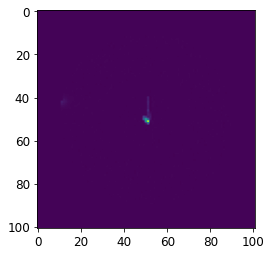

2015-10-04T13:03:33 4340.58785942492 0.25026624068157616 7.377668308702791


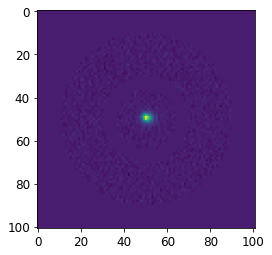

2015-10-04T13:34:14 4312.589456869009 0.9366347177848775 8.018062397372741


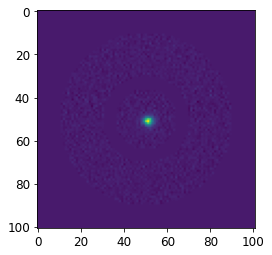

2015-10-04T14:01:06 -407.4840255591054 1.6970181043663473 1.0279146141215108


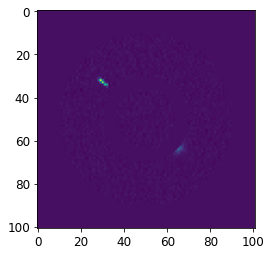

2015-10-04T14:26:37 4236.8873801916925 -0.3889776357827476 6.568144499178982


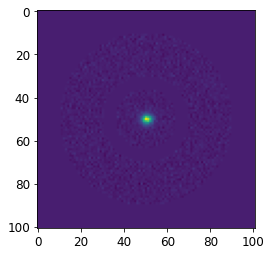

2015-10-04T14:52:01 4497.825079872205 3.1759850905218316 10.561576354679802


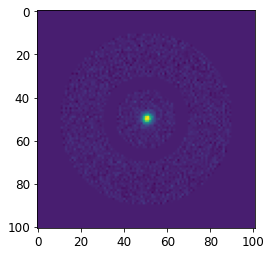

2015-10-04T15:15:59 4761.260383386581 -2.4552715654952078 5.362889983579639


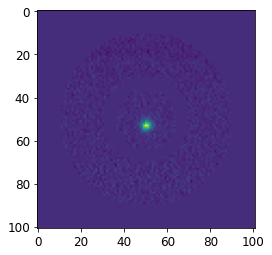

2015-10-04T15:40:38 4526.404153354633 0.6512247071352503 8.083743842364532


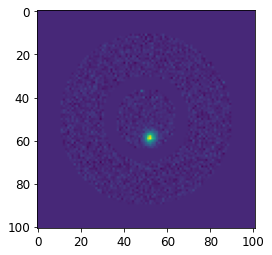

2015-10-04T16:13:48 4204.685303514376 0.1187433439829606 7.022988505747127


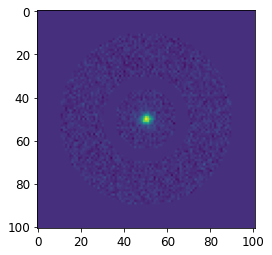

2015-10-04T16:37:56 4292.145367412141 0.7928647497337593 7.8407224958949095


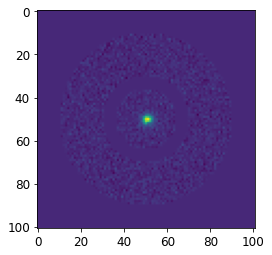

2015-10-04T17:02:03 4492.23801916933 0.6022364217252396 7.9786535303776684


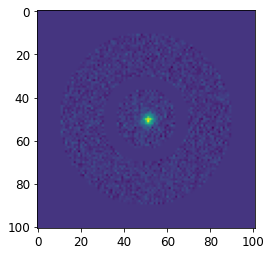

2015-10-04T17:28:25 3802.962460063898 -0.12965921192758253 6.114942528735632


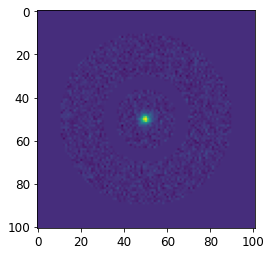

2015-10-04T17:46:31 3804.884185303514 0.9049520766773163 7.152709359605911


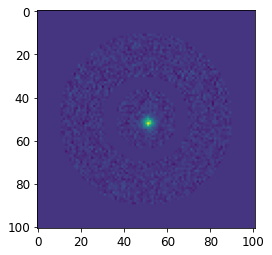

2015-10-04T18:04:48 3921.906549520767 0.18077742279020234 6.620689655172414


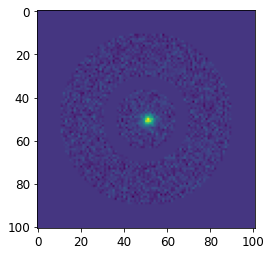

2015-10-04T21:06:25 1417.5247603836278 6758.805378061767 6761.133004926109


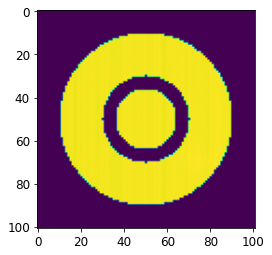

2015-10-04T21:38:32 6804.920926517572 0.02476038338658147 11.198686371100164


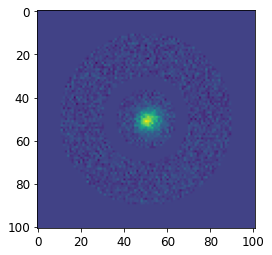

2015-10-04T22:06:58 7569.880990415336 -0.13445154419595315 12.295566502463053


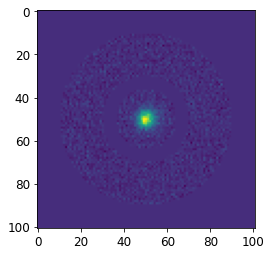

2015-10-04T22:35:54 7430.805910543131 -0.060436634717784876 12.141215106732348


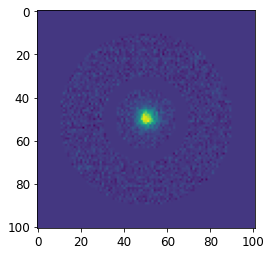

2015-10-04T22:59:12 7501.585463258786 0.22071352502662406 12.538587848932677


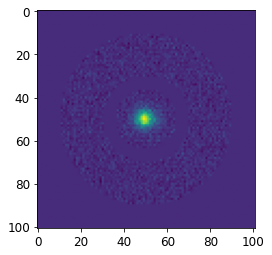

2015-10-04T23:25:02 7201.38178913738 0.04206602768903089 11.866995073891626


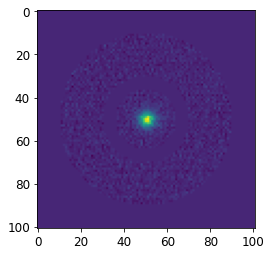

2015-10-04T23:47:09 7254.384185303515 0.07161874334398297 11.983579638752053


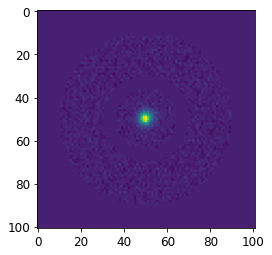

2015-10-05T00:08:39 6421.554313099041 -0.16347177848775293 10.380952380952381


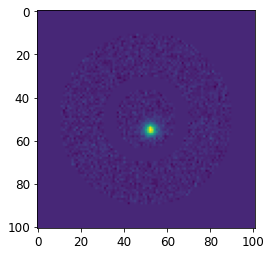

2015-10-05T00:32:37 6656.861022364216 0.28594249201277955 11.216748768472906


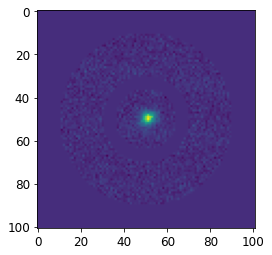

2015-10-05T00:52:52 7375.932108626198 -0.17066027689030883 11.94088669950739


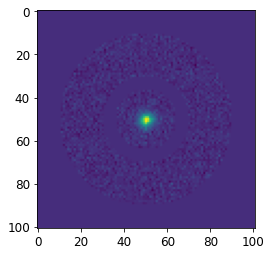

2015-10-05T01:14:05 7387.6972843450485 -0.06682641107561235 12.064039408866995


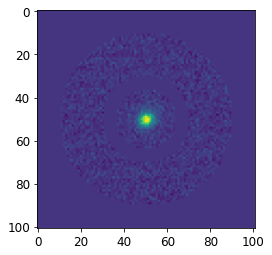

2015-10-05T01:34:46 7265.722044728434 -0.09478168264110756 11.835796387520526


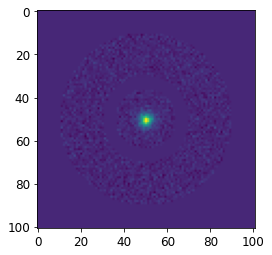

2015-10-05T01:56:07 7084.518370607028 0.05990415335463259 11.692939244663382


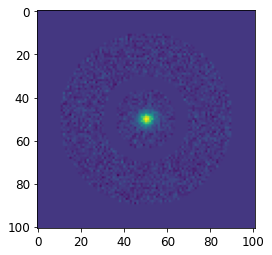

2015-10-05T02:17:46 7291.170127795527 -0.2350905218317359 11.737274220032841


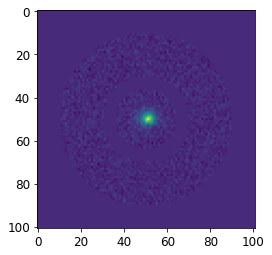

2015-10-05T02:39:50 7132.8115015974445 -0.3248136315228967 11.38752052545156


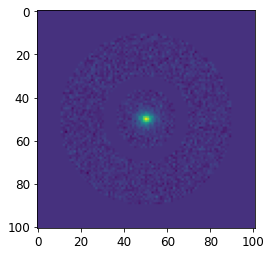

2015-10-06T02:30:12 900.6046325878594 -0.5428647497337593 0.9359605911330049


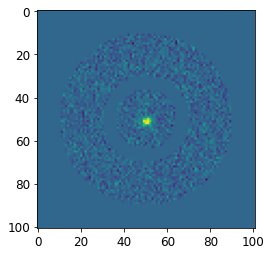

2015-10-06T02:53:14 -20.95207667731643 -0.07561235356762513 -0.11001642036124795


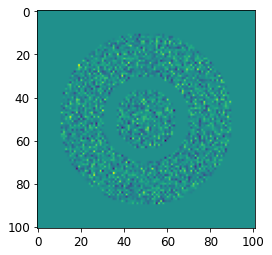

2015-10-06T03:13:58 2064.188498402556 -0.34185303514376997 3.0476190476190474


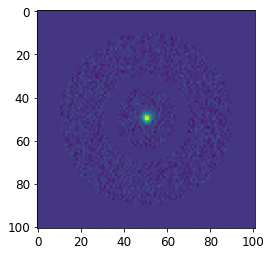

2015-10-06T03:35:41 283.39696485622994 -0.10410010649627263 0.361247947454844


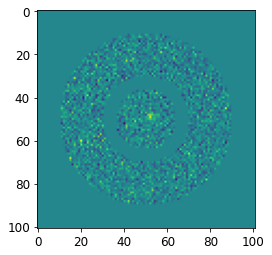

2015-10-06T04:04:01 1881.8825878594253 -0.4480830670926518 2.6420361247947457


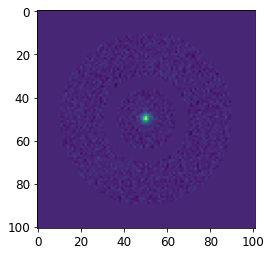

2015-10-06T04:28:16 963.8043130990417 -0.4134717784877529 1.1691297208538587


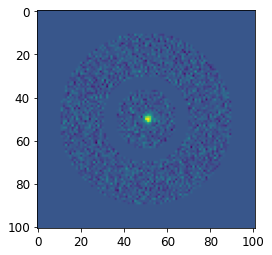

2015-10-06T05:30:42 6405.0279552715665 0.34478168264110753 10.862068965517242


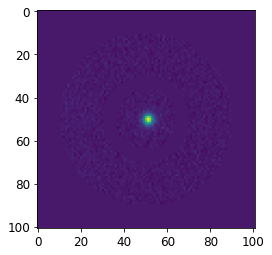

2015-10-06T05:53:46 306.5495207667731 -0.22257720979765708 0.28078817733990147


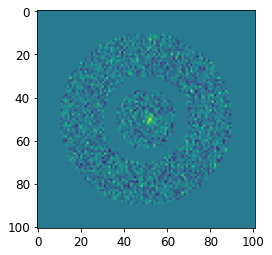

2015-10-06T06:15:03 8402.809904153353 0.6554845580404686 14.45320197044335


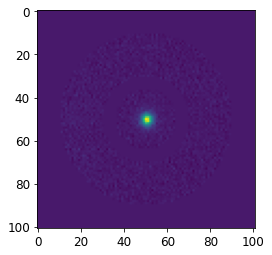

2015-10-06T06:35:19 7856.288338658148 0.5561767838125665 13.456486042692939


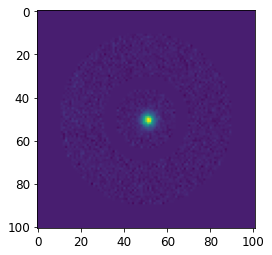

2015-10-06T06:55:22 2704.0319488817895 0.06070287539936102 4.500821018062397


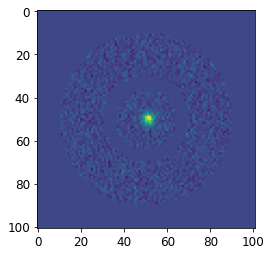

2015-10-06T07:14:50 3404.6693290734825 0.25505857294994677 5.845648604269294


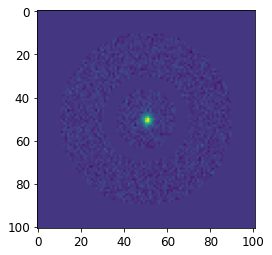

2015-10-06T07:34:20 1855.265974440895 0.2803514376996805 3.3267651888341545


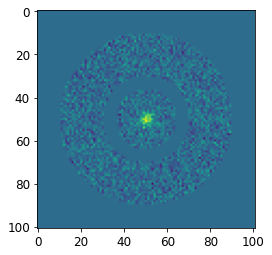

2015-10-06T20:56:31 7305.808306709265 -0.6975505857294995 11.298850574712644


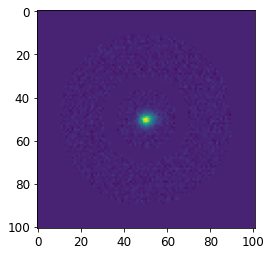

2015-10-06T21:23:45 12262.461661341857 2.3604898828541 22.495894909688012


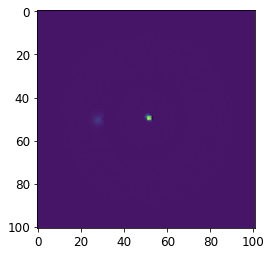

2015-10-06T21:57:14 7122.35782747604 -4.25346112886049 7.441707717569787


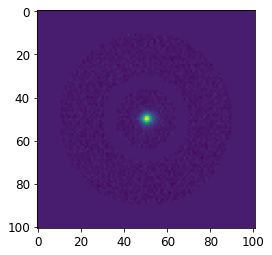

2015-10-06T22:28:23 7736.4936102236425 0.42119275825346114 13.124794745484401


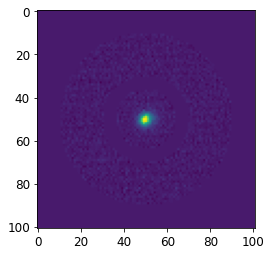

2015-10-06T22:52:37 7999.103035143769 0.2707667731629393 13.405582922824301


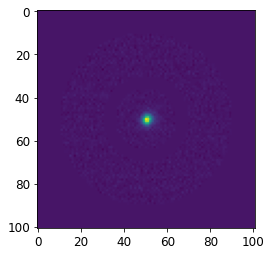

2015-10-06T23:44:49 8527.70287539936 0.3354632587859425 14.338259441707718


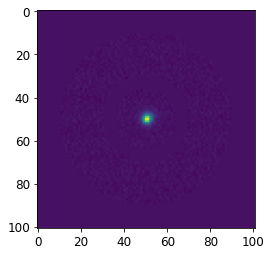

2015-10-07T00:07:05 7200.272364217252 -14.64084132055378 -2.8177339901477834


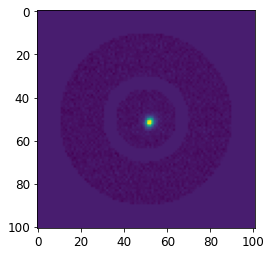

2015-10-07T00:39:16 8448.720447284344 0.21884984025559107 14.091954022988507


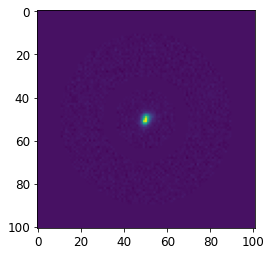

2015-10-07T01:05:26 8040.190095846645 0.34451544195953143 13.54679802955665


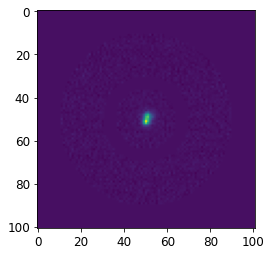

2015-10-07T01:27:23 6213.253993610224 0.13258785942492013 10.334975369458128


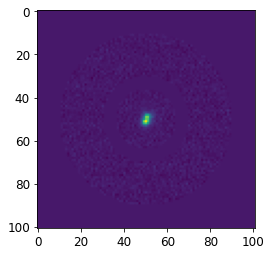

2015-10-07T01:53:11 5402.7092651757175 0.4142705005324814 9.285714285714286


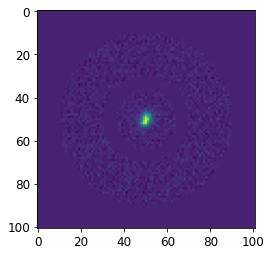

2015-10-07T02:13:35 5733.427316293931 0.27023429179978703 9.68472906403941


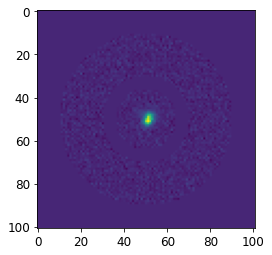

2015-10-08T02:27:47 7378.276357827475 0.4084132055378062 12.523809523809524


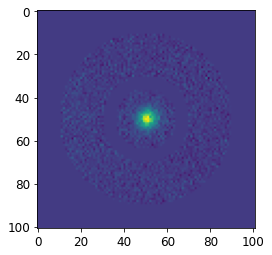

2015-10-08T02:53:26 2503.7308306709265 0.013578274760383386 4.124794745484401


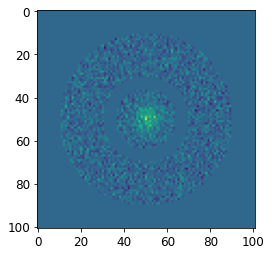

2015-10-08T03:15:18 6139.409744408946 -0.2798189563365282 9.801313628899836


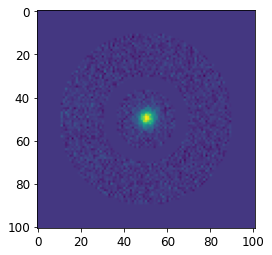

2015-10-08T03:40:39 6108.395367412141 -0.12380191693290735 9.9064039408867


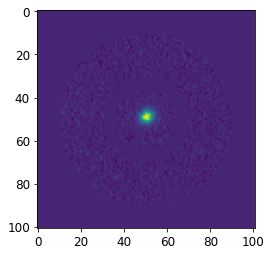

2015-10-08T04:05:28 7020.301916932908 0.056975505857294995 11.58456486042693


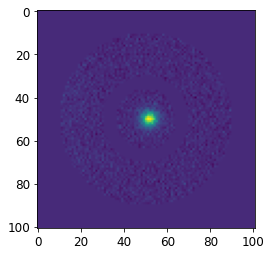

2015-10-08T04:34:48 8984.154153354631 -0.09877529286474973 14.653530377668309


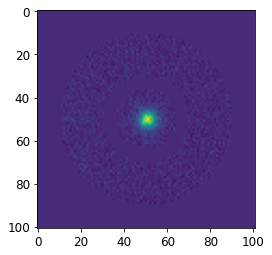

2015-10-08T05:01:12 8550.465654952075 0.4097444089456869 14.44991789819376


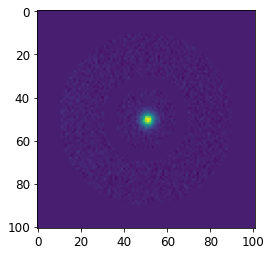

2015-10-08T05:27:03 8330.190095846645 0.011182108626198083 13.689655172413794


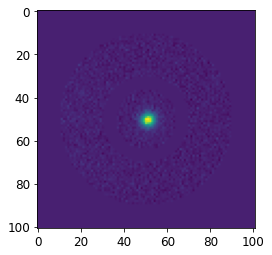

2015-10-08T05:51:43 6695.145367412139 -0.5404685835995741 10.45320197044335


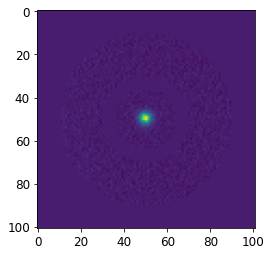

2015-10-08T06:14:07 7056.230830670927 -0.48642172523961663 11.10016420361248


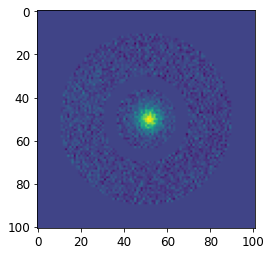

2015-10-08T06:41:37 7316.119009584664 -0.5322151224707136 11.48111658456486


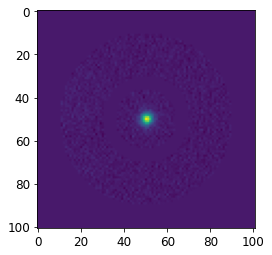

2015-10-08T07:05:41 6704.650958466454 -0.9715122470713525 10.037766830870279


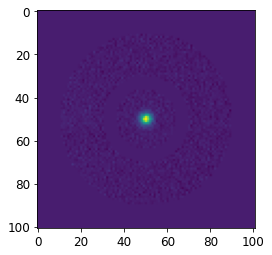

2015-10-08T07:29:31 2058.247603833866 -1.6128860489882855 1.7668308702791462


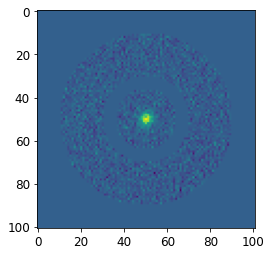

2015-10-08T07:50:12 898.80910543131 -1.6876996805111821 -0.21182266009852216


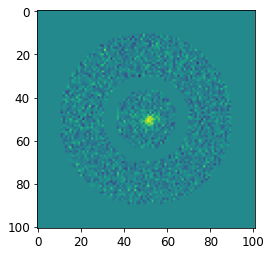

2015-10-08T08:09:00 1435.5279552715656 -1.4885516506922258 0.8686371100164204


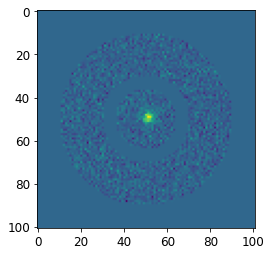

2015-10-08T08:26:36 1122.400159744409 -1.73136315228967 0.1116584564860427


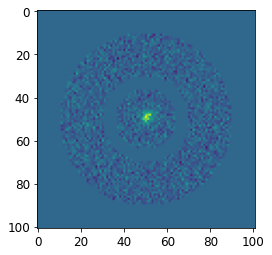

2015-10-08T08:43:43 2629.6861022364214 -1.871405750798722 2.4466338259441707


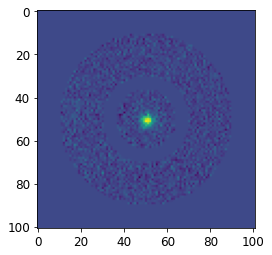

2015-10-08T08:51:05 2697.0966453674114 -1.8080404685835996 2.6206896551724137


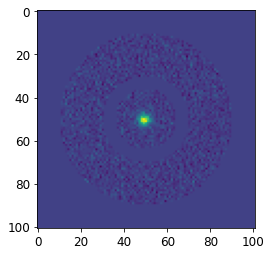

2015-10-08T08:59:27 1476.9624600638974 -2.1296592119275823 0.2955665024630542


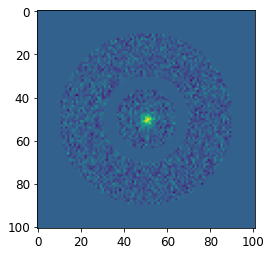

2015-10-08T11:51:40 4830.008785942491 0.10835995740149094 8.039408866995075


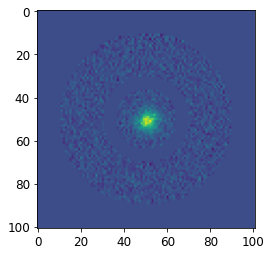

2015-10-08T12:13:31 4859.535143769969 -0.06656017039403621 7.912972085385879


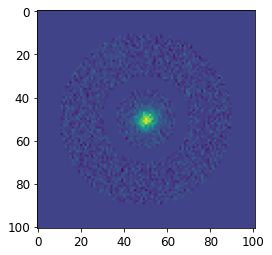

2015-10-08T12:36:12 4802.275559105432 0.06522896698615549 7.9507389162561575


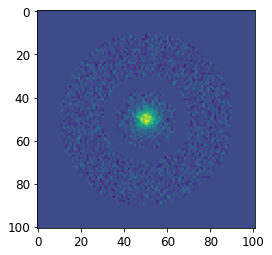

2015-10-08T12:58:19 4534.303514376997 -0.2566560170394036 7.188834154351396


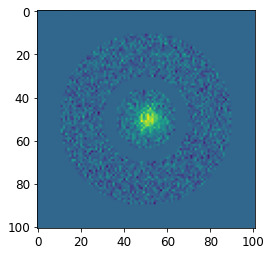

2015-10-08T13:24:01 4828.003993610224 0.049254526091586794 7.977011494252873


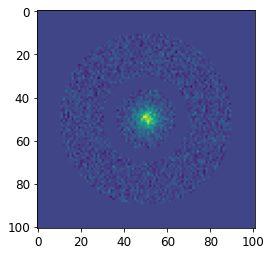

2015-10-08T13:49:06 5272.911341853035 0.23988285410010649 8.898193760262727


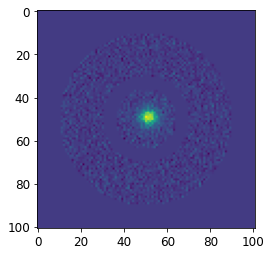

2015-10-08T14:14:52 5074.3785942492 0.3359957401490948 8.668308702791462


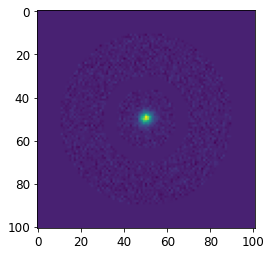

2015-10-08T14:40:06 5433.843450479235 0.402555910543131 9.32512315270936


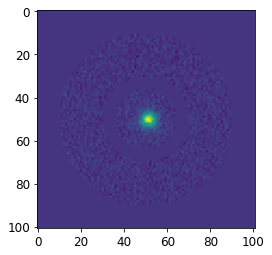

2015-10-08T15:03:15 4819.617412140576 0.2814164004259851 8.195402298850574


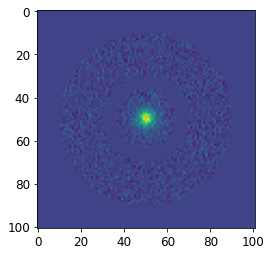

2015-10-08T15:25:48 5086.530351437699 0.20766773162939298 8.559934318555008


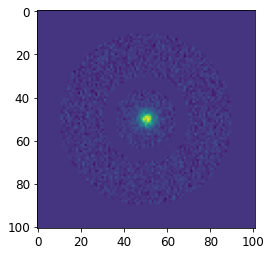

2015-10-08T15:49:14 4804.861821086262 0.29579339723109693 8.185550082101805


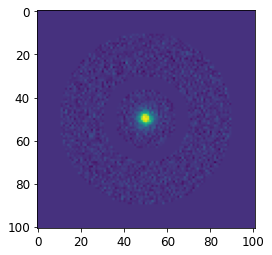

2015-10-08T16:11:39 4739.246006389777 0.03407880724174654 7.816091954022989


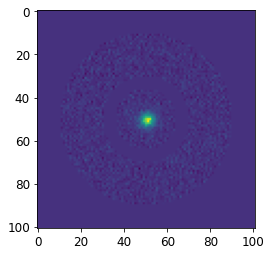

2015-10-08T16:40:21 4784.550319488819 0.45394036208732697 8.310344827586206


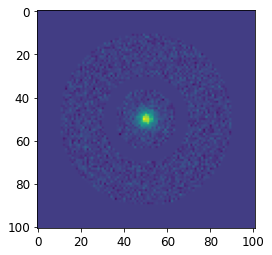

2015-10-08T17:02:21 4707.972044728435 -0.011448349307774228 7.719211822660099


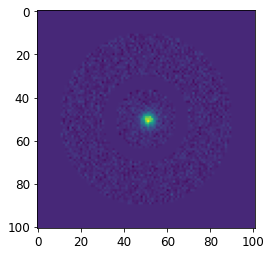

2015-10-08T17:14:53 4810.031150159745 0.05085197018104366 7.949096880131363


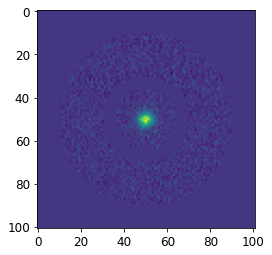

2015-10-08T17:30:00 4761.2651757188505 0.27050053248136313 8.088669950738916


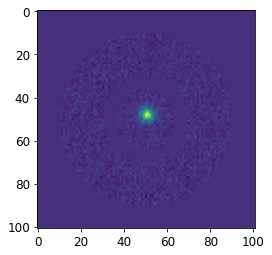

2015-10-08T17:44:30 4945.503194888179 0.20607028753993611 8.326765188834154


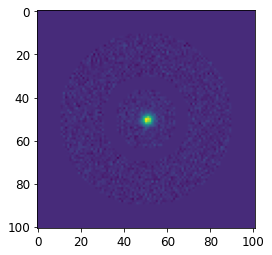

2015-10-08T17:53:00 4429.977635782748 0.3908413205537806 7.665024630541872


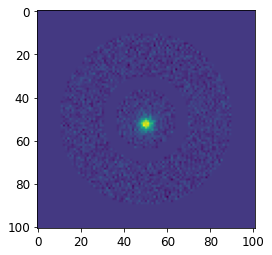

2015-10-08T18:07:24 4425.89536741214 0.04286474973375932 7.310344827586207


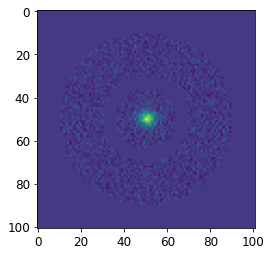

2015-10-08T18:14:38 4095.5047923322686 -0.10756123535676251 6.617405582922824


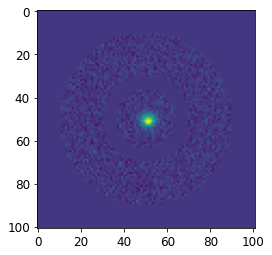

2015-10-08T21:14:56 8776.77875399361 0.2712992545260916 14.683087027914613


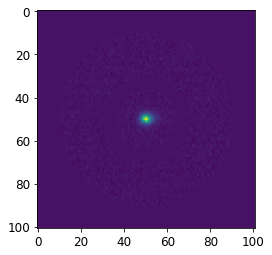

2015-10-08T21:40:23 8763.846645367414 0.7752928647497338 15.16584564860427


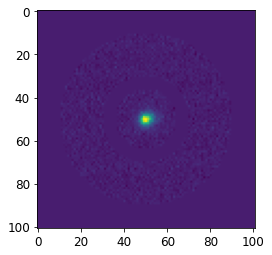

2015-10-08T22:09:40 7398.598242811502 0.37832800851970183 12.527093596059114


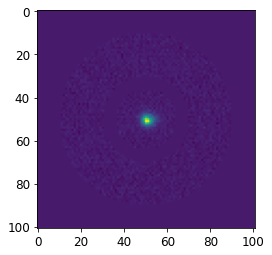

2015-10-08T22:37:29 7722.602236421726 0.760915867944622 13.441707717569786


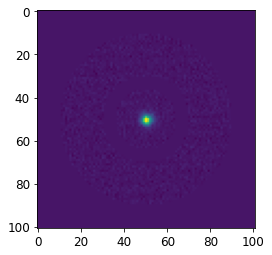

2015-10-08T23:02:34 9184.611821086262 0.8791267305644302 15.960591133004925


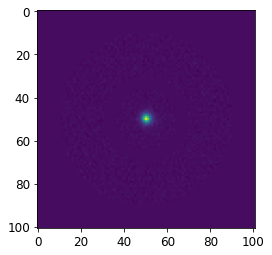

2015-10-08T23:33:05 8082.749201277957 0.9068157614483493 14.178981937602627


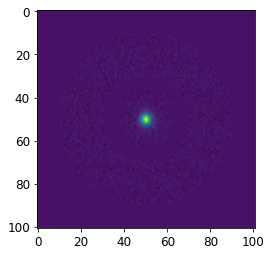

2015-10-08T23:54:27 8578.61661341853 0.6048988285410011 14.691297208538588


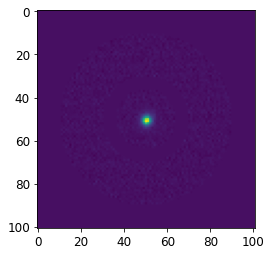

2015-10-09T00:15:57 9011.585463258785 0.5540468583599574 15.351395730706075


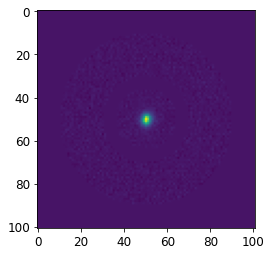

2015-10-09T00:38:23 8864.143769968054 0.4398296059637913 14.995073891625616


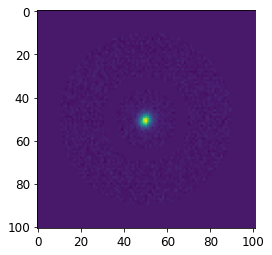

2015-10-09T00:59:56 7833.089456869009 0.4366347177848775 13.298850574712644


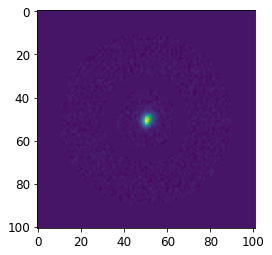

2015-10-09T01:23:03 7562.325878594249 0.6858359957401491 13.10344827586207


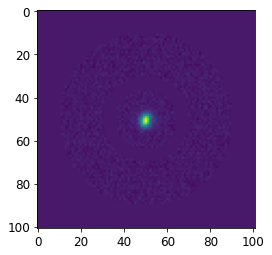

2015-10-09T01:44:16 7897.022364217252 0.6091586794462194 13.576354679802956


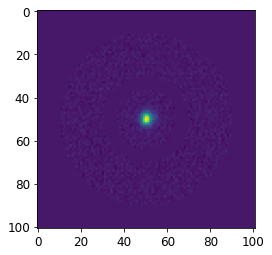

2015-10-09T02:05:54 7996.61821086262 0.6246006389776357 13.755336617405582


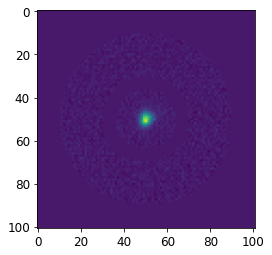

2015-10-10T02:25:36 2342.3378594249198 0.8335995740149095 4.679802955665025


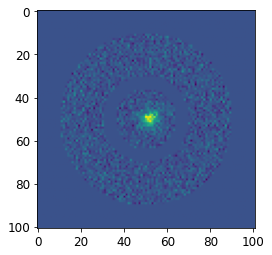

2015-10-10T11:56:37 4786.902555910543 0.13152289669861555 7.991789819376026


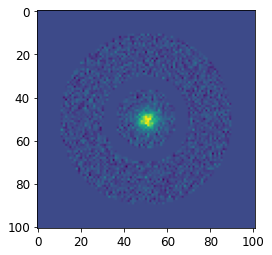

2015-10-10T12:18:45 603.5327476038336 0.5705537806176784 1.561576354679803


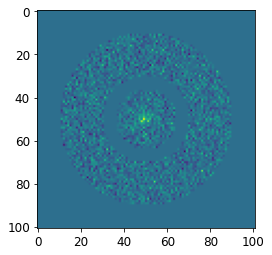

2015-10-10T12:41:35 4489.403354632588 -0.3586261980830671 7.013136288998358


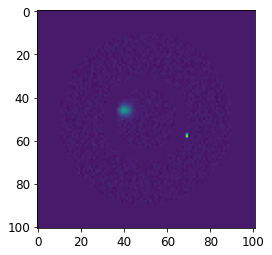

2015-10-10T13:06:33 4705.730031948882 0.003727369542066028 7.730706075533662


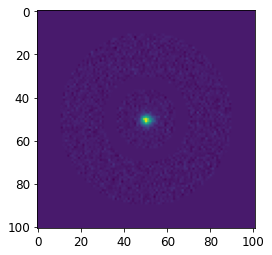

2015-10-10T13:32:33 4916.534345047923 0.25692225772097976 8.330049261083744


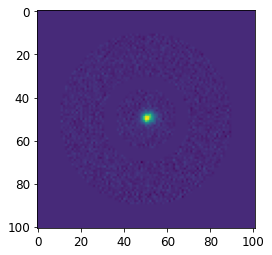

2015-10-10T14:10:07 4313.95607028754 0.12486687965921192 7.208538587848933


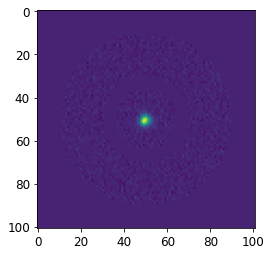

2015-10-10T14:33:05 2620.0351437699683 0.4334398296059638 4.735632183908046


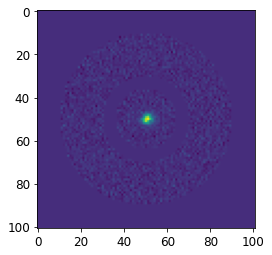

2015-10-10T14:56:16 5041.989616613419 0.20527156549520767 8.48440065681445


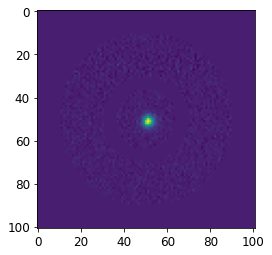

2015-10-10T15:20:15 4618.654952076677 0.0777422790202343 7.661740558292283


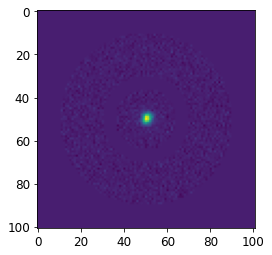

2015-10-10T15:41:54 4654.815495207668 0.05777422790202343 7.7011494252873565


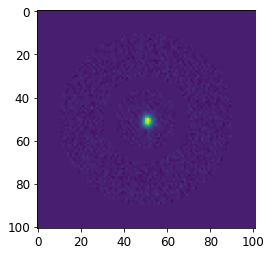

2015-10-10T16:04:19 4444.000798722044 0.3431842385516507 7.640394088669951


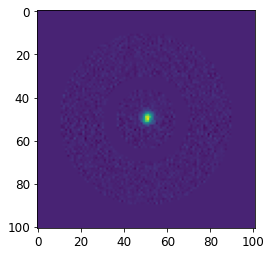

2015-10-10T16:27:20 4162.452875399362 0.25212992545260915 7.087027914614121


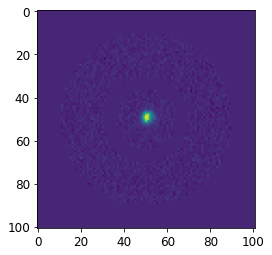

2015-10-10T20:35:09 10757.265974440896 -0.05298189563365282 17.610837438423644


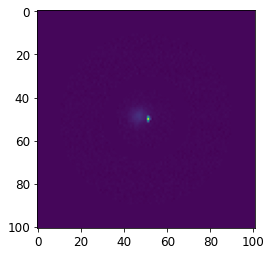

2015-10-10T21:02:38 7779.685303514377 0.4520766773162939 13.226600985221674


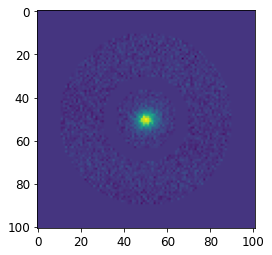

2015-10-10T21:35:18 8918.174920127794 -0.17598509052183173 14.467980295566502


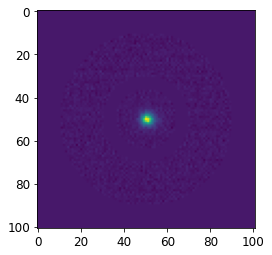

2015-10-10T22:07:39 9023.967252396165 -0.07055378061767838 14.74712643678161


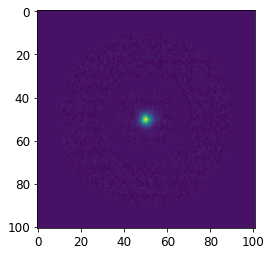

2015-10-10T22:35:17 8924.730830670926 0.013578274760383386 14.668308702791462


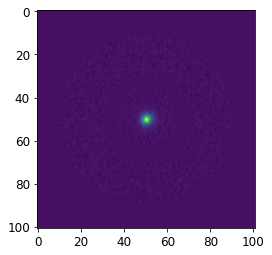

2015-10-10T22:57:44 212.8035143769964 31.910010649627264 32.25944170771757


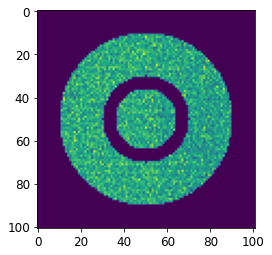

2015-10-10T23:19:23 9524.734025559104 -0.2803514376996805 15.35960591133005


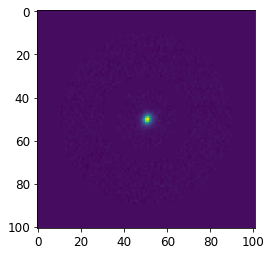

2015-10-10T23:40:37 9371.208466453674 0.23775292864749734 15.625615763546797


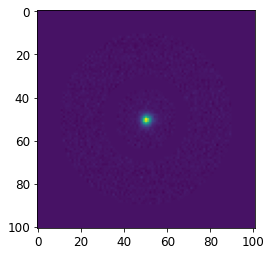

2015-10-11T00:01:11 8746.97603833866 -0.2955271565495208 14.067323481116585


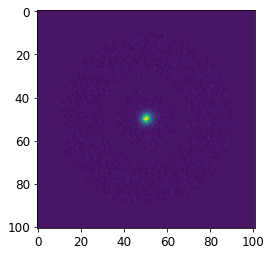

2015-10-11T00:25:51 8688.205271565495 -0.13498402555910544 14.13136288998358


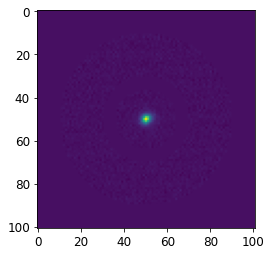

2015-10-11T00:46:42 8796.829872204475 -0.4315761448349308 14.013136288998359


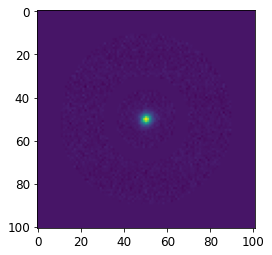

2015-10-11T01:09:55 8674.335463258785 -0.1959531416400426 14.047619047619047


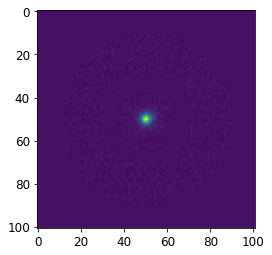

2015-10-11T01:31:24 8684.5303514377 -0.12566560170394037 14.13464696223317


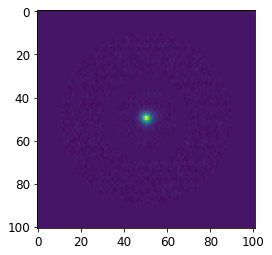

2015-10-11T01:53:09 8164.10143769968 -0.4156017039403621 12.990147783251231


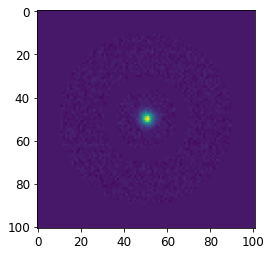

2015-10-11T02:14:12 8197.980031948882 -0.24627263045793396 13.215106732348112


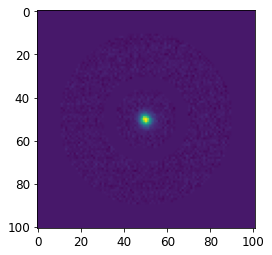

2015-10-12T02:05:45 6670.998402555911 0.646964856230032 11.600985221674877


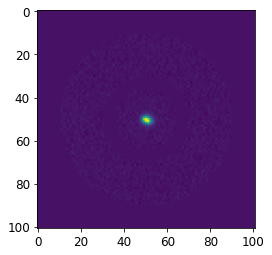

2015-10-12T02:27:39 7357.0702875399365 0.5335463258785943 12.614121510673234


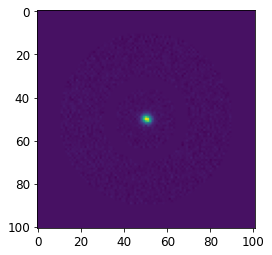

2015-10-12T02:54:03 5366.380990415336 -0.3011182108626198 8.510673234811167


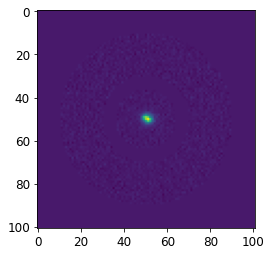

2015-10-12T03:18:51 -2684.920127795527 3.6517571884984026 -0.7569786535303776


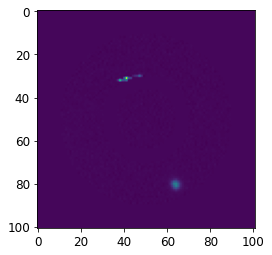

2015-10-12T03:47:15 8086.984025559106 0.13631522896698617 13.41543513957307


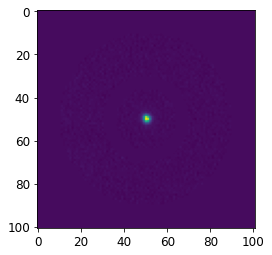

2015-10-12T04:12:45 6583.007188498402 -0.2446751863684771 10.564860426929393


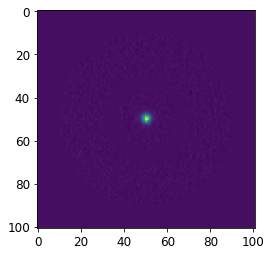

2015-10-12T04:36:12 7339.896166134185 0.38604898828541 12.438423645320198


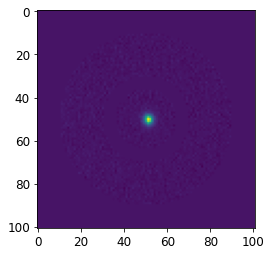

2015-10-12T04:58:57 3048.261980830671 -0.10223642172523961 4.90311986863711


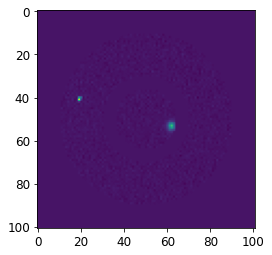

2015-10-12T05:05:57 1608.5479233226836 -0.5756123535676251 2.0656814449917897


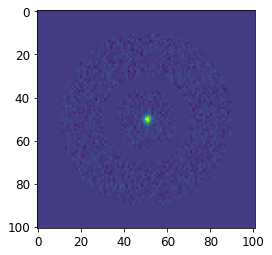

2015-10-12T05:23:40 287.10543130990425 -0.3663471778487753 0.10509031198686371


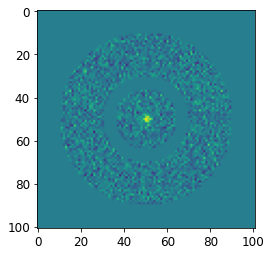

2015-10-12T20:11:38 7759.775559105432 0.5652289669861554 13.307060755336618


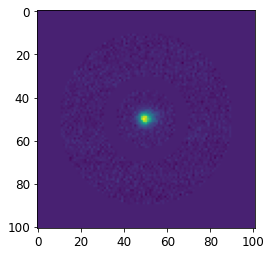

2015-10-12T20:43:12 8275.255591054312 0.48562300319488816 14.073891625615763


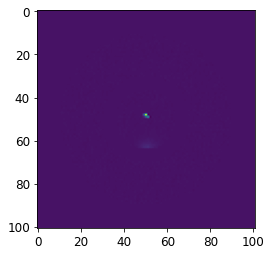

2015-10-12T21:14:27 7726.157348242812 0.273961661341853 12.960591133004925


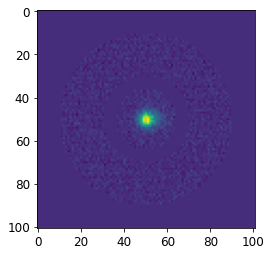

2015-10-12T21:52:43 8042.192492012779 0.3740681576144835 13.579638752052546


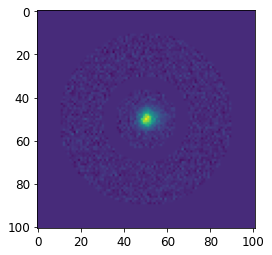

2015-10-12T22:25:26 8023.460063897763 0.3407880724174654 13.51559934318555


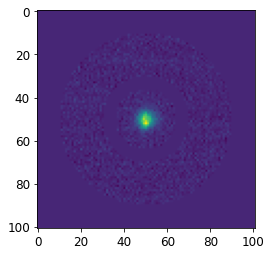

2015-10-12T22:48:17 7656.220447284345 0.3855165069222577 12.957307060755337


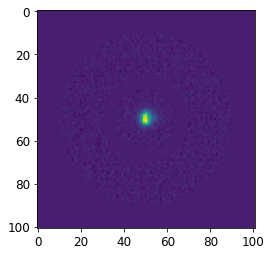

2015-10-12T23:09:50 7584.567092651758 0.6608093716719915 13.114942528735632


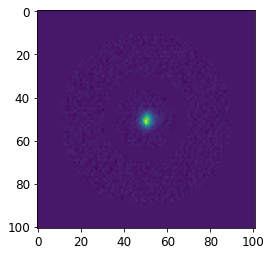

2015-10-12T23:31:54 8018.69408945687 0.22710330138445153 13.394088669950738


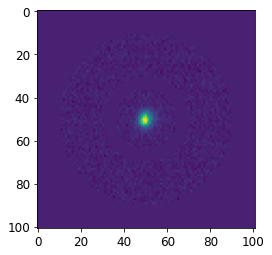

2015-10-12T23:52:08 7602.36661341853 0.1882321618743344 12.67159277504105


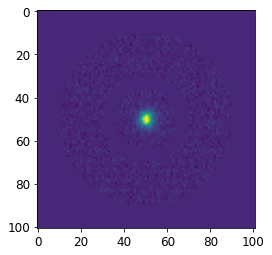

2015-10-13T00:12:14 7944.3666134185305 0.1882321618743344 13.233169129720855


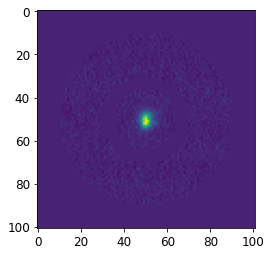

2015-10-13T00:33:25 7754.164536741214 0.36261980830670926 13.095238095238095


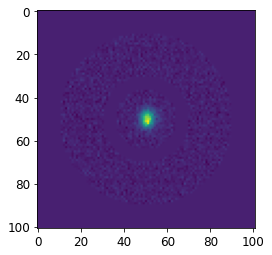

2015-10-13T00:55:16 7589.400159744409 0.26863684771033014 12.730706075533663


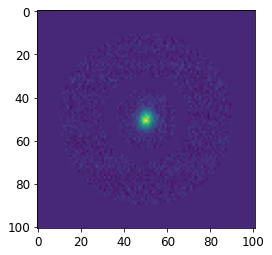

2015-10-13T01:24:03 7251.743610223642 0.5045260915867945 12.412151067323482


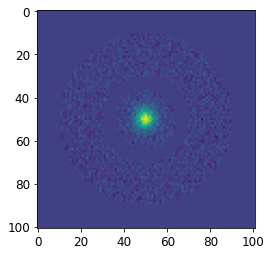

2015-10-13T01:48:13 7002.238019169329 0.6022364217252396 12.10016420361248


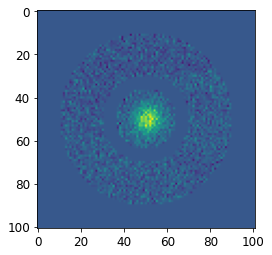

2015-10-14T11:38:34 3713.6709265175714 -0.058572949946751864 6.039408866995074


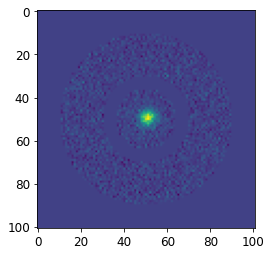

2015-10-14T12:01:53 3964.460063897763 0.007454739084132056 6.517241379310345


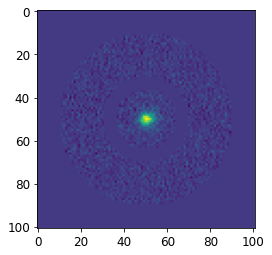

2015-10-14T12:24:06 3770.869009584665 0.051118210862619806 6.2430213464696225


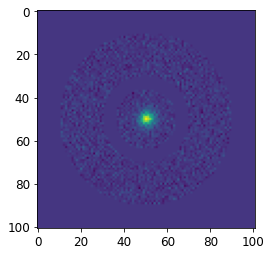

2015-10-14T12:46:30 3793.753194888179 -0.0439297124600639 6.185550082101806


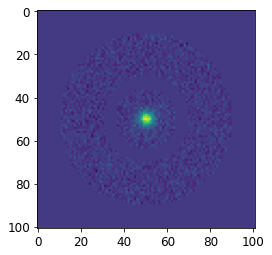

2015-10-14T13:12:39 3836.2515974440885 0.10303514376996806 6.402298850574713


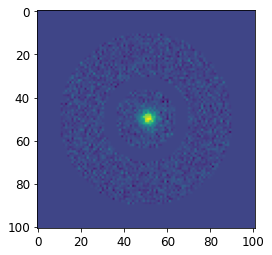

2015-10-14T13:37:28 1164.0798722044728 0.9850905218317358 2.896551724137931


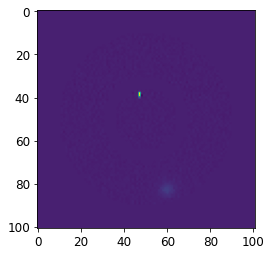

2015-10-14T14:00:12 3955.8554313099044 -0.1163471778487753 6.379310344827586


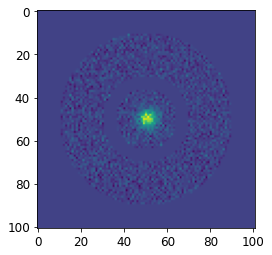

2015-10-14T14:24:16 3586.0151757188496 0.18716719914802982 6.075533661740558


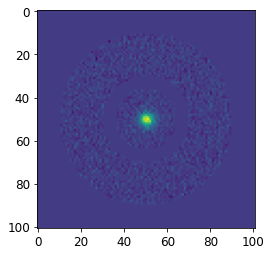

2015-10-14T14:45:44 3662.965654952077 -0.0902555910543131 5.924466338259442


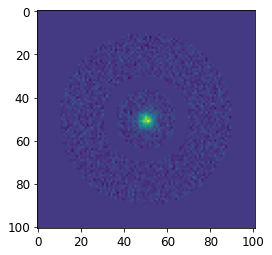

2015-10-14T15:07:01 3821.025559105432 -0.01810436634717785 6.25615763546798


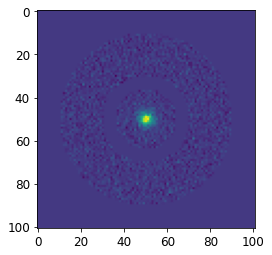

2015-10-14T15:28:52 3528.738817891374 0.11208732694355697 5.906403940886699


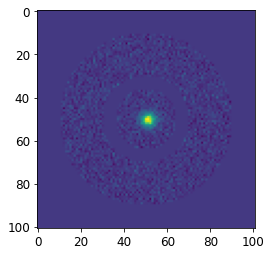

2015-10-14T15:49:52 3587.1134185303513 0.06549520766773163 5.955665024630542


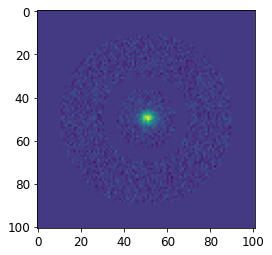

2015-10-14T16:11:44 3878.2723642172527 0.02582534611288605 6.394088669950739


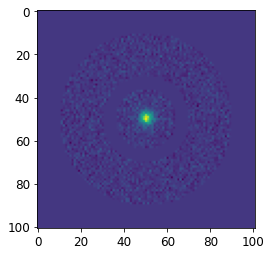

2015-10-14T16:33:14 3836.3921725239616 -0.16320553780617678 6.136288998357964


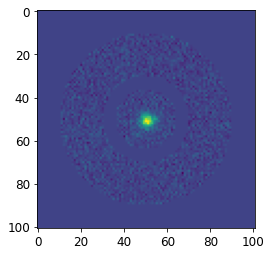

2015-10-14T16:47:06 3452.0638977635776 0.4547390841320554 6.123152709359606


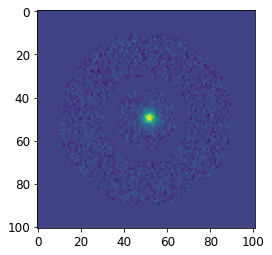

2015-10-14T17:01:52 3954.2859424920134 0.19329073482428116 6.686371100164203


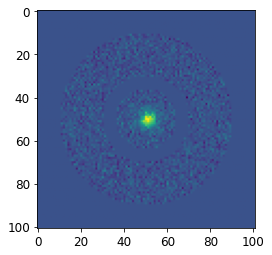

2015-10-14T17:15:24 3350.2028753993613 -0.49787007454739085 5.003284072249589


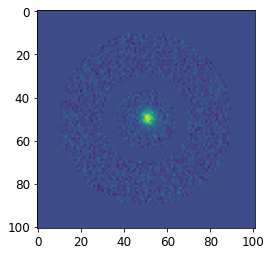

2015-10-14T17:22:25 2953.207667731629 0.22790202342917998 5.077175697865353


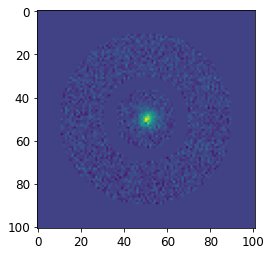

2015-10-14T17:29:09 3304.025559105431 -0.01810436634717785 5.407224958949097


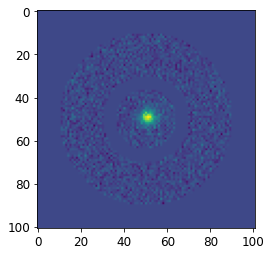

2015-10-14T17:35:56 3212.283546325878 0.16373801916932906 5.438423645320197


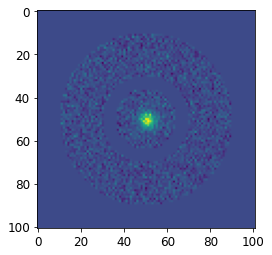

2015-10-14T17:42:48 3074.0551118210865 0.013045793397231097 5.060755336617405


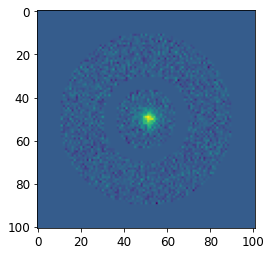

2015-10-14T17:50:25 3066.114217252396 0.07534611288604899 5.110016420361248


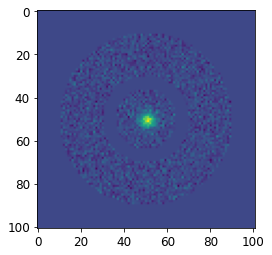

2015-10-16T11:26:45 3067.3338658146963 0.11767838125665601 5.154351395730706


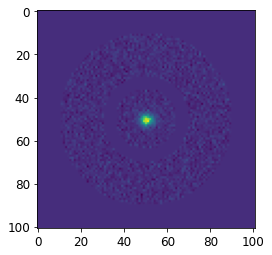

2015-10-16T11:48:42 2847.95447284345 0.1051650692225772 4.781609195402299


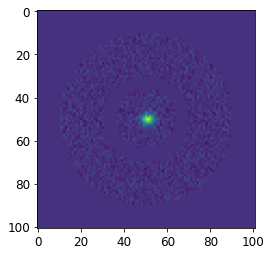

2015-10-16T12:10:07 2975.697284345048 -0.06682641107561235 4.819376026272578


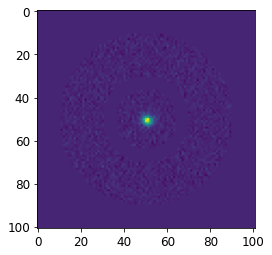

2015-10-16T12:33:26 2927.74840255591 0.23029818956336529 5.037766830870279


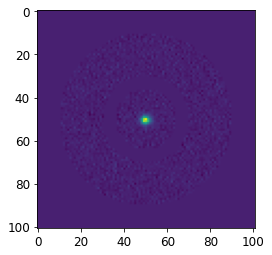

2015-10-17T11:18:48 2798.6006389776358 -0.5921192758253461 4.003284072249589


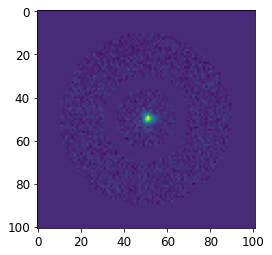

2015-10-17T11:40:32 2247.559904153355 -1.0945154419595313 2.5960591133004924


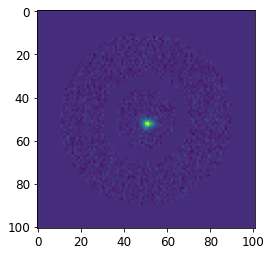

2015-10-17T12:02:26 2454.9752396166136 -0.3053780617678381 3.7257799671592773


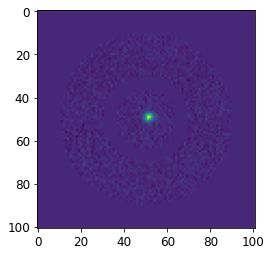

2015-10-17T12:24:22 1961.1477635782753 0.15575079872204473 3.3760262725779966


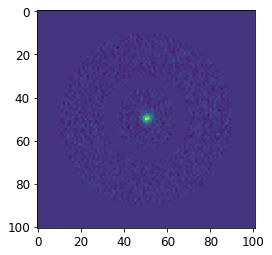

2015-10-19T11:19:58 2149.495207667732 0.10756123535676251 3.6371100164203614


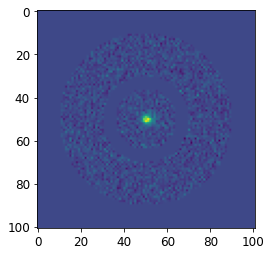

2015-10-19T11:44:22 2075.9273162939294 -0.229765708200213 3.1789819376026274


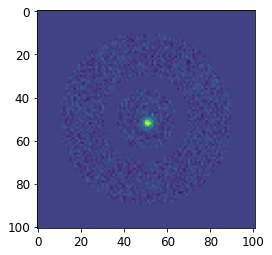

2015-10-19T12:08:04 1663.729233226837 -0.006123535676251331 2.7257799671592773


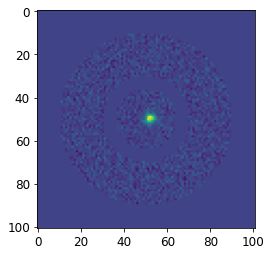

2015-10-19T12:31:29 2048.9448881789135 -0.013045793397231097 3.3513957307060753


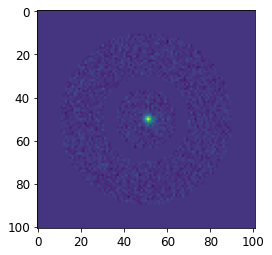

2015-10-19T12:57:39 1941.0678913738018 0.17066027689030883 3.3579638752052543


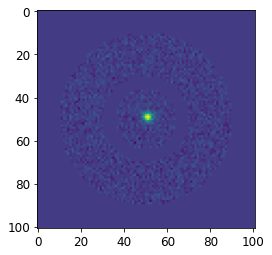

2015-10-20T11:10:51 1483.3610223642177 0.11927582534611289 2.555008210180624


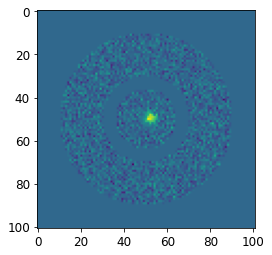

2015-10-20T11:33:58 1800.9624600638979 -0.12965921192758253 2.8275862068965516


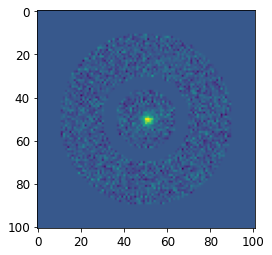

2015-10-20T11:57:59 1604.2555910543128 -0.1810436634717785 2.4532019704433496


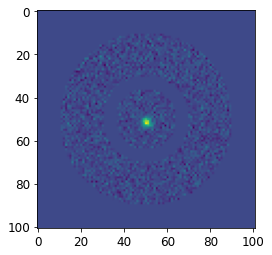

2015-10-20T12:25:27 1597.7515974440898 -0.06363152289669861 2.5599343185550083


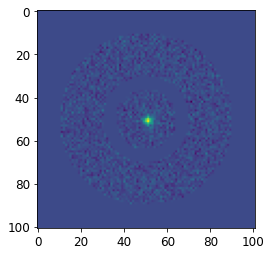

2015-10-21T00:09:31 1664.755591054313 1.6522896698615548 4.385878489326765


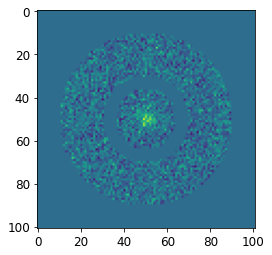

2015-10-21T00:30:36 1687.1126198083073 0.722310969116081 3.4926108374384235


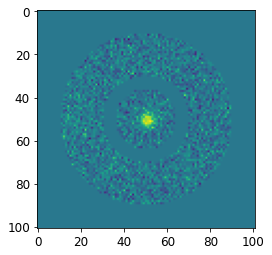

2015-10-21T00:49:22 1888.1789137380192 0.5399361022364217 3.6403940886699506


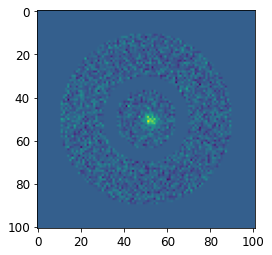

2015-10-21T01:11:29 2288.418530351438 0.4952076677316294 4.252873563218391


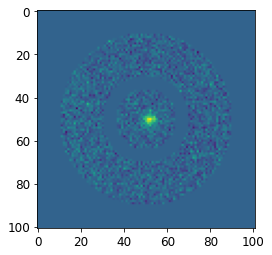

2015-10-21T01:33:52 2441.422523961661 0.5444621938232161 4.553366174055829


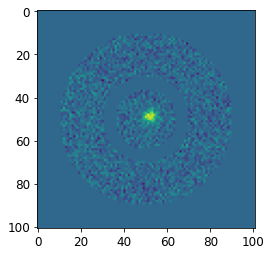

2015-10-22T00:19:51 1972.6285942492016 1.0859957401490947 4.325123152709359


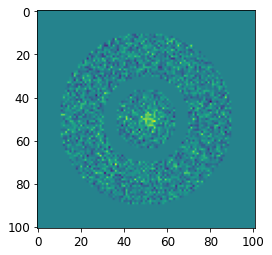

2015-10-22T00:40:45 2163.518370607029 0.7265708200212992 4.279146141215107


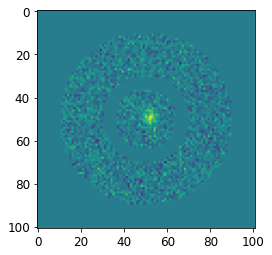

2015-10-22T01:02:00 1718.5047923322684 0.8924387646432375 3.7142857142857144


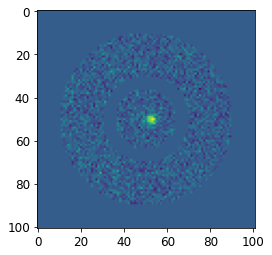

2015-10-22T01:22:04 2276.111821086262 1.0457933972310969 4.783251231527093


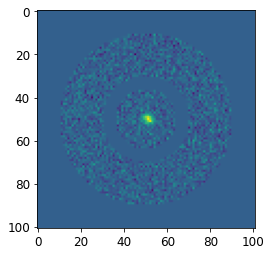

2015-10-22T01:42:01 2885.296325878594 -0.011980830670926517 4.725779967159277


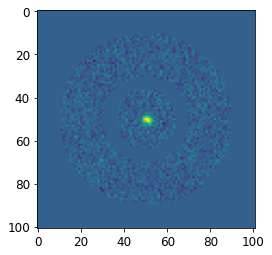

2015-10-23T10:03:21 1841.5343450479234 -2.409744408945687 0.6141215106732348


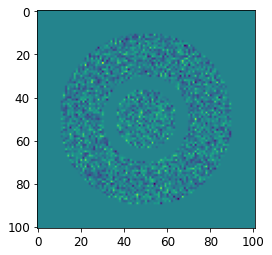

2015-10-23T10:24:41 1540.5854632587857 -2.4459531416400426 0.08374384236453201


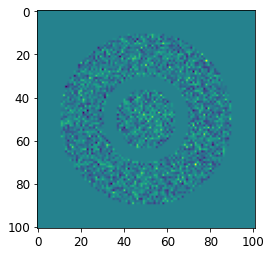

2015-10-23T10:50:21 1037.6285942492011 -2.2473375931842385 -0.5435139573070608


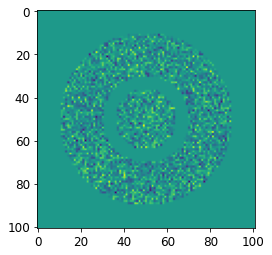

2015-10-24T00:10:35 2050.333865814697 0.11767838125665601 3.48440065681445


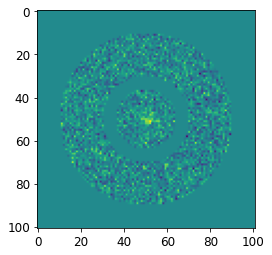

2015-10-24T00:32:32 2731.207667731629 0.22790202342917998 4.712643678160919


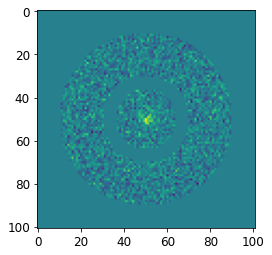

2015-10-24T00:52:50 1022.5623003194886 0.9350372736954207 2.6141215106732347


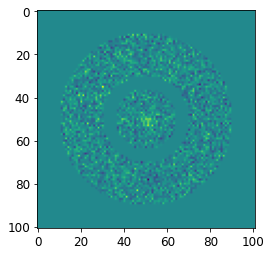

2015-10-24T01:14:04 3082.555910543131 0.5228966986155484 5.584564860426929


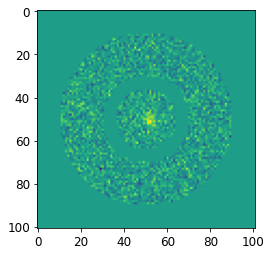

2015-10-24T01:36:02 1476.6749201277953 0.990681576144835 3.4154351395730704


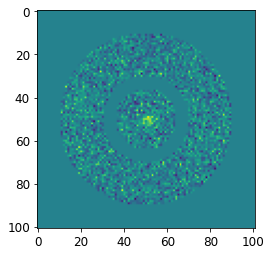

2015-10-24T09:54:08 1641.559904153355 -11.761182108626198 -9.06568144499179


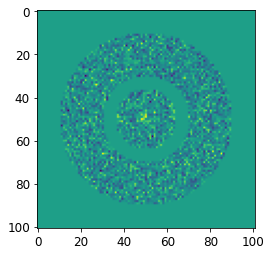

2015-10-24T10:15:39 2419.3418530351437 -5.4504792332268375 -1.477832512315271


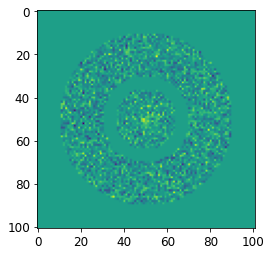

2015-10-24T10:36:49 320.65015974440985 -5.648029818956337 -5.121510673234811


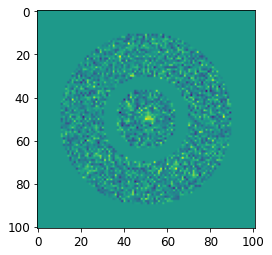

2015-10-24T10:57:59 1117.095047923323 -5.827742279020234 -3.993431855500821


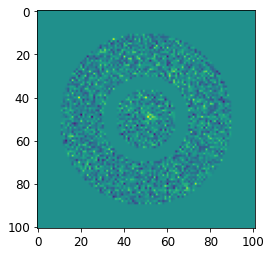

2015-10-25T10:11:55 718.7995207667711 -40.13924387646432 -38.95894909688013


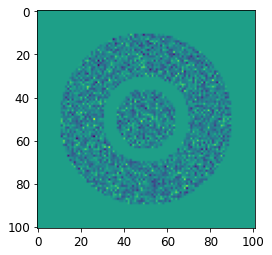

2015-10-25T10:37:30 588.8857827476052 -9.075346112886049 -8.108374384236454


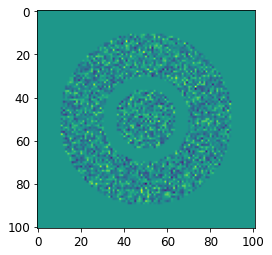

2015-10-26T00:18:34 693.5630990415336 -2.3884451544195953 -1.2495894909688012


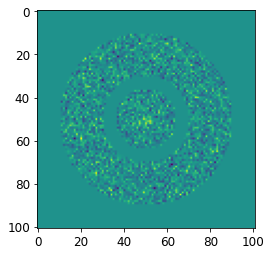

2015-10-26T00:38:29 164.44808306709257 -2.140308839190628 -1.8702791461412152


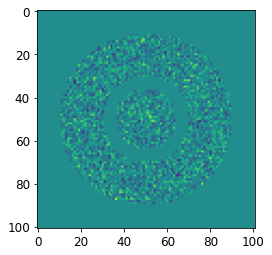

2015-10-26T00:58:44 1395.4648562300317 -45.60010649627263 -43.308702791461414


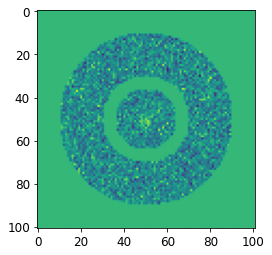

2015-10-26T01:19:49 -2.68769968051015 51.851703940362086 51.847290640394085


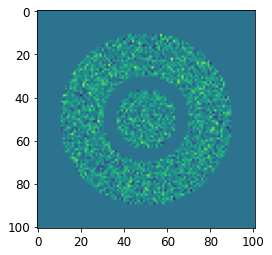

2015-10-26T01:40:59 1427.3554313099048 5.050319488817891 7.394088669950739


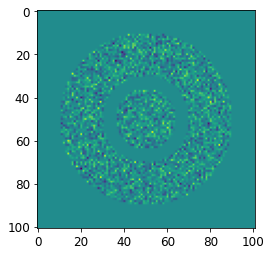

2015-10-26T02:04:58 -1341.1741214057524 -29.147497337593183 -31.34975369458128


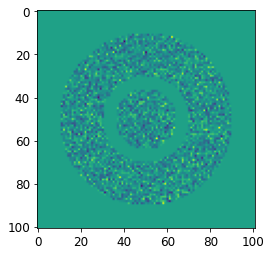

2015-10-27T00:22:42 1570.6277955271566 -2.5905218317358893 -0.011494252873563218


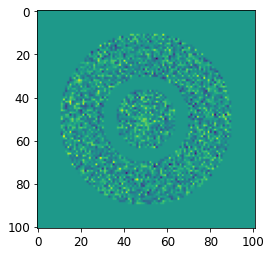

2015-10-27T00:43:29 2279.6765175718865 33.3437167199148 37.08702791461412


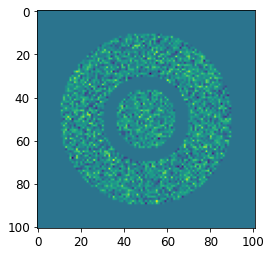

2015-10-27T01:03:59 653.9680511182095 -2.060702875399361 -0.986863711001642


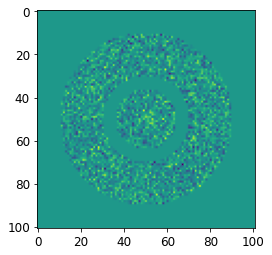

2015-10-27T01:25:14 1308.3658146964851 -1.4882854100106497 0.6600985221674877


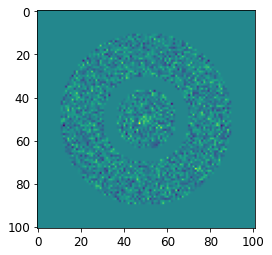

2015-10-27T01:46:58 529.1198083067102 -1.8556975505857296 -0.986863711001642


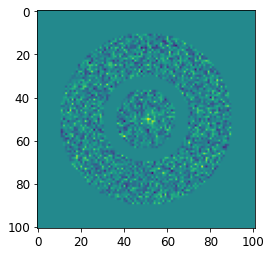

2015-10-27T02:09:11 657.2531948881791 -1.543929712460064 -0.46469622331691296


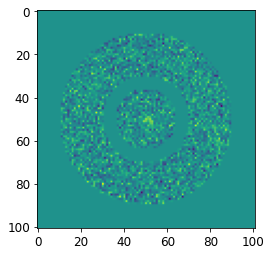

2015-10-27T02:32:06 -246.4928115015972 -1.4113418530351438 -1.8160919540229885


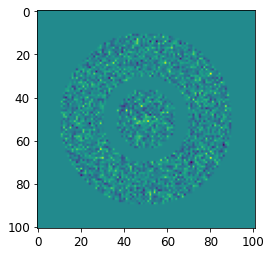

2015-10-27T02:54:29 -52.104632587860436 -0.6238019169329073 -0.7093596059113301


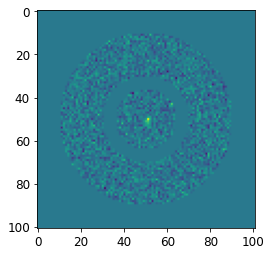

2015-10-27T03:18:43 628.4169329073478 -2.5244941427050054 -1.4926108374384237


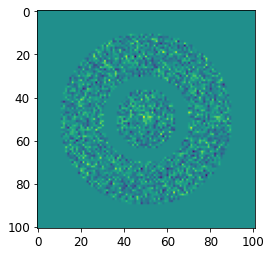

2015-10-27T03:43:25 1587.2739616613421 -2.6211395101171457 -0.014778325123152709


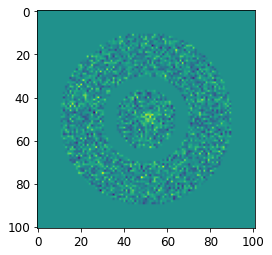

2015-10-27T04:11:04 1063.0423322683707 -3.8112353567625132 -2.0656814449917897


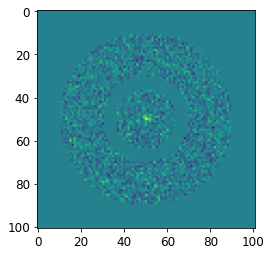

2015-10-27T04:31:52 1282.11821086262 -2.2087326943556977 -0.10344827586206896


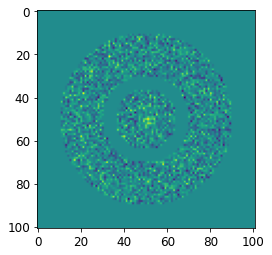

2015-10-27T04:52:52 1301.0247603833873 -3.3612886048988284 -1.2249589490968802


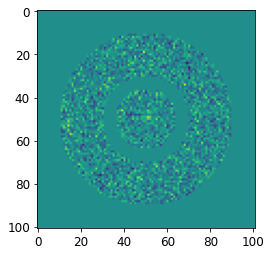

2015-10-27T05:14:40 -163.93370607028703 -2.849041533546326 -3.1182266009852215


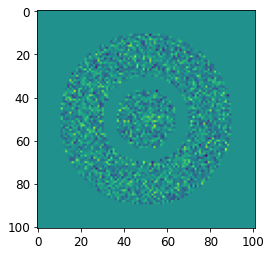

2015-10-27T05:35:57 31.469648562300733 -3.207667731629393 -3.1559934318555007


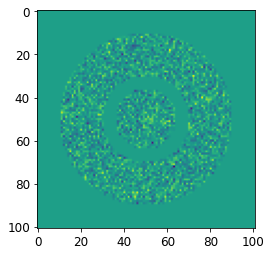

2015-10-27T05:57:14 2497.13019169329 -3.3943024494142704 0.7060755336617406


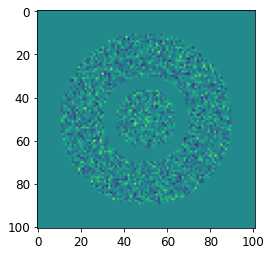

2015-10-27T06:23:09 489.04632587859425 -3.428647497337593 -2.625615763546798


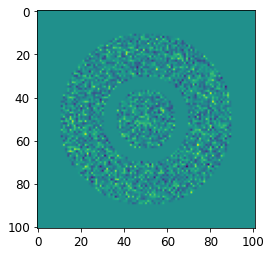

2015-10-27T06:44:43 643.8530351437685 -4.145899893503727 -3.0886699507389164


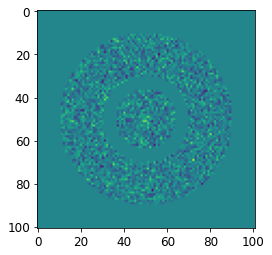

2015-10-27T07:05:19 -917.8370607028754 -6.9904153354632586 -8.497536945812808


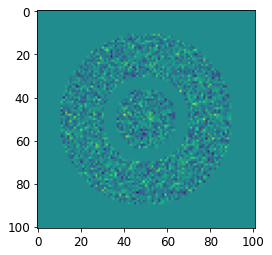

2015-10-27T07:19:45 56.049520766771366 -5.389243876464324 -5.297208538587849


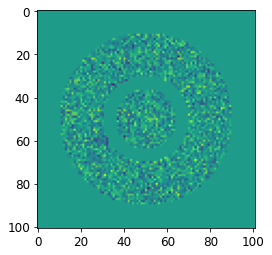

2015-10-27T07:32:54 -72.23162939297096 -5.5234291799787005 -5.642036124794745


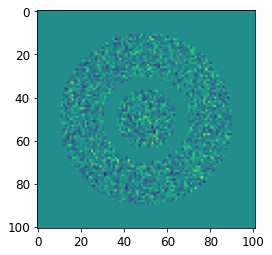

2015-10-27T07:37:39 1484.0806709265185 -6.005058572949947 -3.568144499178982


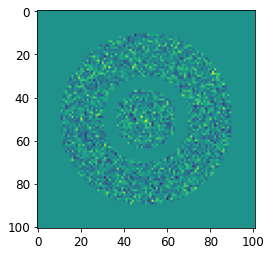

2015-10-27T07:51:38 -1289.4864217252407 5.334132055378062 3.2167487684729066


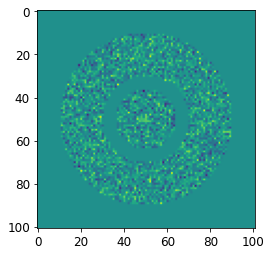

2015-10-28T10:13:57 636.2883386581466 -2.4438232161874334 -1.3990147783251232


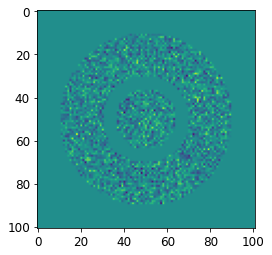

2015-10-28T10:36:23 124.42012779552647 -3.1517571884984026 -2.947454844006568


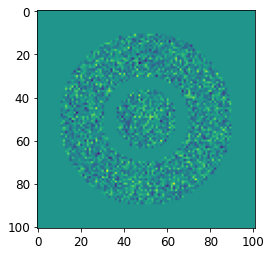

2015-10-28T10:58:35 1471.5774760383392 -2.8777955271565494 -0.4614121510673235


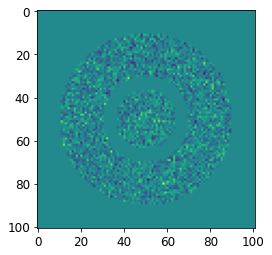

2015-10-29T00:21:42 827.1789137380194 0.873269435569755 2.231527093596059


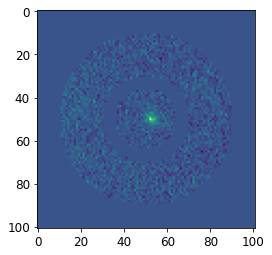

2015-10-29T00:43:13 1190.6405750798724 1.2337593184238551 3.1888341543513956


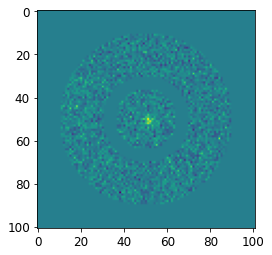

2015-10-29T01:06:22 665.1765175718854 0.843716719914803 1.935960591133005


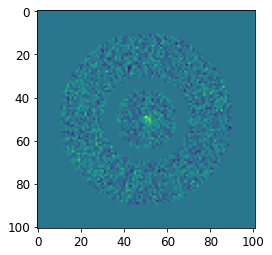

2015-10-29T01:26:52 6.923322683705763 1.7209797657082002 1.7323481116584565


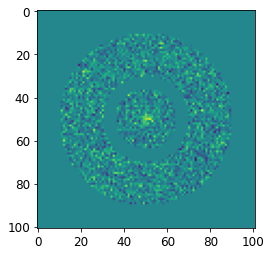

2015-10-29T01:47:57 653.2108626198087 1.6006389776357828 2.6732348111658455


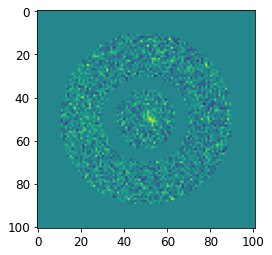

2015-10-29T02:12:51 849.7324281150156 1.033280085197018 2.4285714285714284


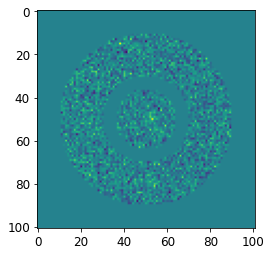

2015-10-29T02:37:29 845.3746006389772 1.6200745473908413 3.0082101806239736


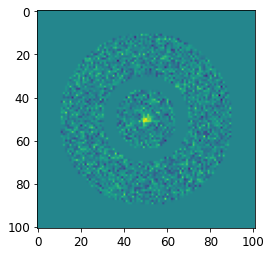

2015-10-29T03:01:01 401.3091054313101 1.4789669861554846 2.1379310344827585


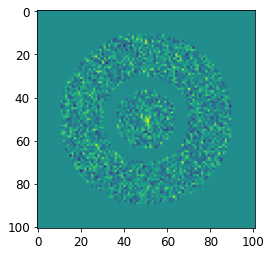

2015-10-29T03:26:05 1382.7699680511187 1.8296059637912674 4.100164203612479


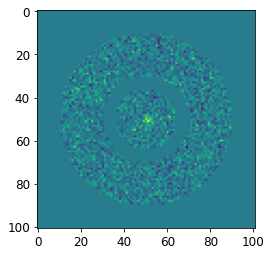

2015-10-29T03:47:35 -1498.5567092651756 1.8005857294994676 -0.6600985221674877


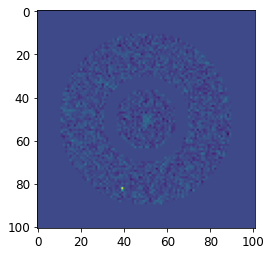

2015-10-29T04:16:55 784.3035143769971 0.7433439829605963 2.0311986863711002


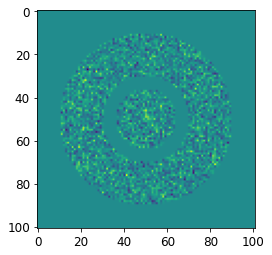

2015-10-29T04:23:23 1357.3418530351432 -0.11714589989350373 2.1116584564860426


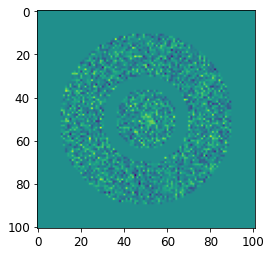

2015-10-29T04:26:47 178.93051118210917 0.8096379126730564 1.103448275862069


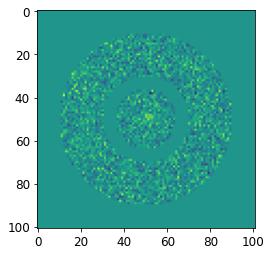

2015-10-29T04:43:35 693.9800319488814 1.753727369542066 2.8932676518883413


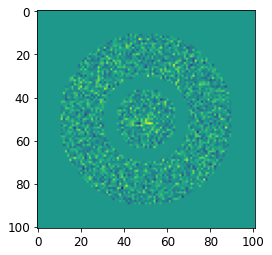

2015-10-29T05:05:17 501.9001597444087 1.1019701810436635 1.9261083743842364


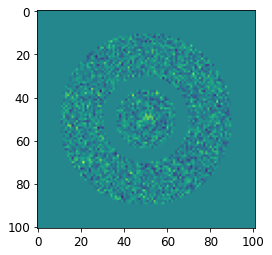

2015-10-29T05:26:25 982.9880191693285 0.5189030883919062 2.1330049261083746


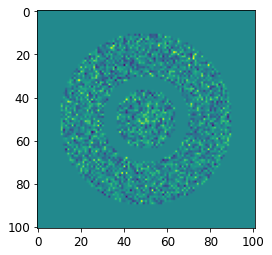

2015-10-29T05:52:06 -364.17252396166265 4.538871139510118 3.9408866995073892


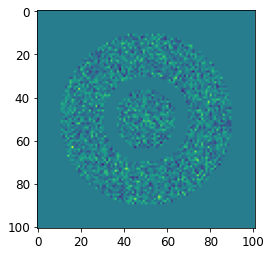

2015-10-29T06:15:32 -161.09345047923478 -9.15255591054313 -9.417077175697866


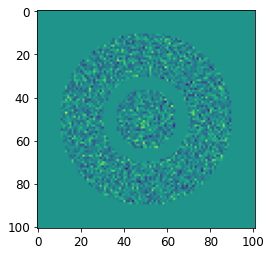

2015-10-29T06:38:40 -662.3626198083067 -4.805644302449414 -5.893267651888341


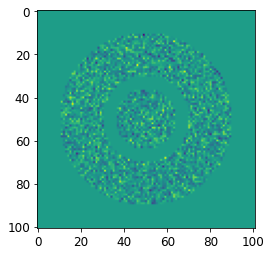

2015-10-29T07:00:16 -167.77316293929675 2.4643237486687966 2.1888341543513956


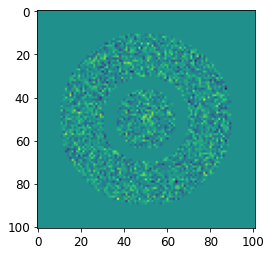

2015-10-29T07:14:01 1359.1956869009573 3.7468051118210863 5.9786535303776684


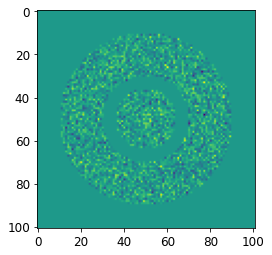

2015-10-29T07:28:01 1779.0615015974436 -20.90814696485623 -17.986863711001643


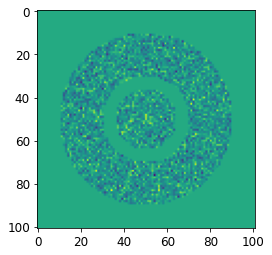

2015-10-29T07:40:59 -762.0854632587875 10.945953141640043 9.694581280788178


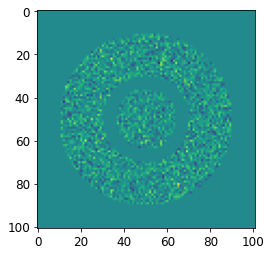

2015-10-29T09:59:18 439.58466453674123 0.2108626198083067 0.9326765188834154


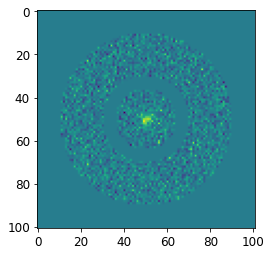

2015-10-29T10:21:06 588.8091054313097 -0.35436634717784876 0.6124794745484401


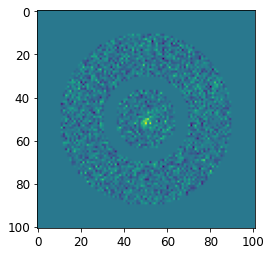

2015-10-29T10:48:48 554.9560702875401 -0.5417997870074548 0.3694581280788177


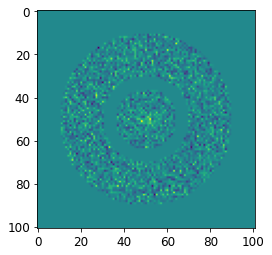

2015-10-30T00:20:06 632.3226837060703 1.6464323748668797 2.684729064039409


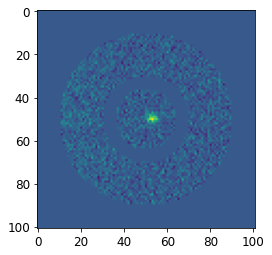

2015-10-30T00:44:48 655.4273162939297 1.270234291799787 2.3464696223316914


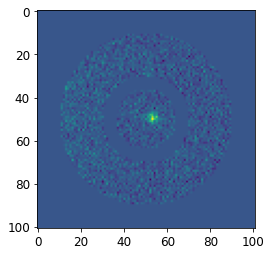

2015-10-30T01:09:10 578.8123003194889 1.018370607028754 1.9688013136288998


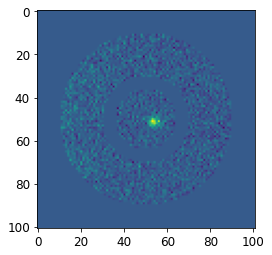

2015-10-30T01:34:52 836.5966453674117 1.6919595314164004 3.0656814449917897


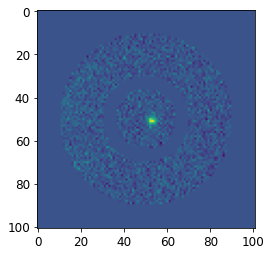

2015-10-30T01:56:16 1099.255591054313 2.152289669861555 3.9573070607553364


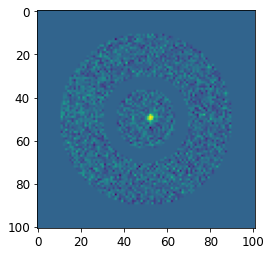

In [5]:
ref_1 = SkyCoord('00h56m49.70s', '-37d01m38.31s')
ref_2 = SkyCoord('00h56m46.43s', '-37d02m29.50s')
ref_3 = SkyCoord('00h56m58.27s', '-36d58m16.60s')

data, header  = read_file(img_files[0])

w = WCS(header)
super_nova = pixel_to_skycoord(data.shape[0]//2,data.shape[1]//2, w)


stars = [ref_1,ref_2,ref_3,super_nova]
boxsize = 50


aperture = get_aperture((2*boxsize + 1, 2*boxsize + 1), 14)
annulus = get_annulus((2*boxsize + 1, 2*boxsize + 1), 20, 40)

plt.imshow(np.zeros_like(aperture)+aperture+annulus)
plt.show()

fluxes = np.empty((len(stars),len(img_files)))

#For image in images
for i, f in enumerate(img_files):
    
    # read the image
    data, header  = read_file(f)
    w = WCS(header)
    
    for j, star in enumerate(stars):
        
        # locate the star
        ref_pos = skycoord_to_pixel(star, w)
        ref_x, ref_y = ref_pos
        ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)

        #generate region around star and get local centroid
        sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, ref_x_int-boxsize: ref_x_int+boxsize+1]
        cent = np.round(centroid(sub_im),0).astype(int)

        #Round to nearest integer, adjust by a few pixels if needed
        ref_x_int += cent[1]
        ref_y_int += cent[0]

        #Generate a new region with a better center
        sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
                      ref_x_int-boxsize: ref_x_int+boxsize+1]

        #Background 
        bg = np.sum(sub_im*annulus)/annulus[annulus>0].size
#         plt.imshow(sub_im*annulus)
#         plt.show()
        #Compute flux
        flux = np.sum((sub_im- bg)*aperture )

        fluxes[j,i] = flux
        if j == 3:
            print(header['DATE-OBS'], flux, bg, np.sum(sub_im*aperture)/aperture[aperture>0].size)
            plt.imshow(sub_im*(aperture + annulus))
            plt.show()
        
#     break

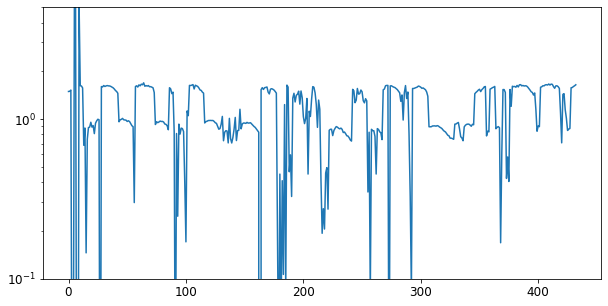

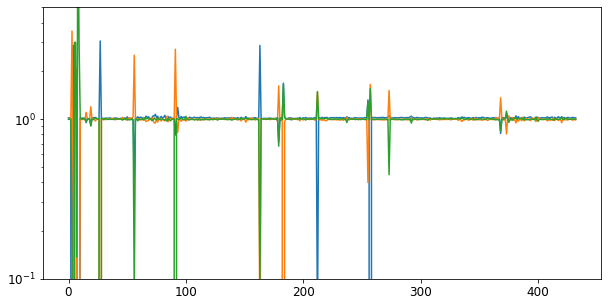

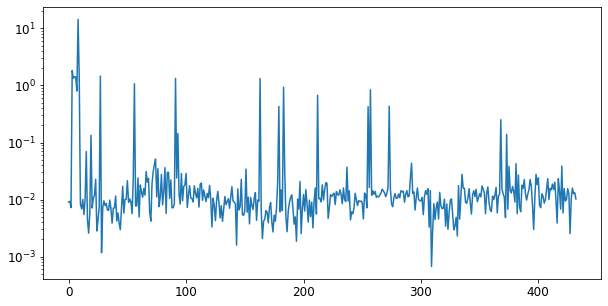

In [6]:
med_over_time = np.empty_like(fluxes[:-1,:])
for i in range(fluxes.shape[0]-1):
    med_over_time[i,:] = fluxes[i,:]/np.median(fluxes[i,:])

med_over_time_and_stars = np.mean(med_over_time, axis = 0)
plt.figure(figsize = (10,5))
plt.plot(med_over_time_and_stars)
plt.yscale('log')
plt.ylim(0.1, 5)
plt.show()


plt.figure(figsize = (10,5))
for i in range(med_over_time.shape[0]):
    med_over_time[i,:] /= med_over_time_and_stars
    plt.plot(med_over_time[i,:])
plt.yscale('log')
plt.ylim(0.1, 5)
plt.show()

# med_calib = np.median(med_over_time, axis = 0)
std_calib = np.std(med_over_time, axis = 0)


# plt.figure(figsize = (10,5))
# plt.plot(file_times,med_calib, 'x')
# plt.yscale('log')
# plt.show()

plt.figure(figsize = (10,5))
plt.plot(std_calib)
plt.yscale('log')
plt.show()

# _filter = (std_calib < 3e-2)&(fluxes[-1,:] > 0)

# plt.figure(figsize = (10,5))
# plt.plot(np.mean(calib_data, axis = 0)[_filter])
# plt.yscale('log')
# plt.ylim(0.1, 5)
# plt.show()

/tmp/ipykernel_4852/1333227732.py:7: RuntimeWarning: invalid value encountered in log10
  ref_lightcurves[i,j,:] = 2.512*np.log10(fluxes[j,:]/cur_star_flux) + ref_mags[j]


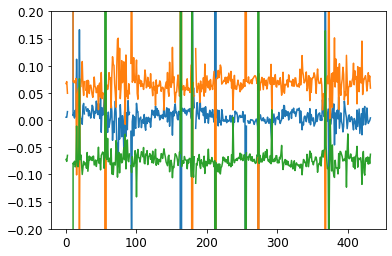

In [7]:
ref_mags = [16.32, 17.16, 15.61]
ref_lightcurves = np.empty((len(stars) - 1, len(stars) - 1, fluxes.shape[1]))

for i in range(ref_lightcurves.shape[0]):
    cur_star_flux = fluxes[i,:]
    for j in range(ref_lightcurves.shape[1]):
        ref_lightcurves[i,j,:] = 2.512*np.log10(fluxes[j,:]/cur_star_flux) + ref_mags[j]


ref_lightcurves = [0.5*(ref_lightcurves[0,1]+ref_lightcurves[0,2]),
                  0.5*(ref_lightcurves[1,0]+ref_lightcurves[1,2]),
                  0.5*(ref_lightcurves[2,0]+ref_lightcurves[2,1])]

for i, curve in enumerate(ref_lightcurves):
    plt.plot(curve - ref_mags[i])
#     plt.axhline(ref_mags[0], color = 'r', linestyle = '--')
plt.ylim(-0.2, 0.2)
plt.show()

_filter = (np.abs(ref_lightcurves[0] - ref_mags[0]) < 0.15)&(np.abs(ref_lightcurves[1] - ref_mags[1]) < 0.15)&(np.abs(ref_lightcurves[2] - ref_mags[2]) < 0.15)&(fluxes[-1,:] > 0)



Hello 3
[18.77631217 18.72368581 18.74400106 18.6917343  18.69087988 18.62694818
 18.72599487 18.67810058 18.74886492 18.72793626 18.70966054 18.71666359
 18.70459601 18.69632117 18.74724713 18.69050107 18.69340104 18.68457544
 18.67320247 18.69050828 18.70678286 18.65105189 18.84631749 18.73315392
         nan 18.84234466 18.77162345 18.7217186  18.77672744 18.72626142
 18.72528527 18.80756935 18.76267767 18.79964058 18.76700427 18.51124913
 18.87465251 18.7756008  18.77105382 18.78925715 17.27644616 18.70598734
 18.71552104 18.77876752 18.78265826 18.76383073 18.76104843 18.74222726
 18.78774439 18.75697788 18.85203104 18.8458393  18.79407391         nan
 18.88690833 18.91100361 18.88916849 19.18964094 18.92048894 19.31200659
 18.8866538  18.81789321 18.89069017 18.86252373 18.87683277 18.9360893
 18.93904547 18.86546833 18.90901066 18.85923972 18.88039863 18.89387419
 18.90643251 18.8752331  19.0757189  19.01446075 19.05488692 19.06028122
 19.06223064 20.35650093 19.02262119 19.1388

/tmp/ipykernel_4852/2474150535.py:8: RuntimeWarning: invalid value encountered in log10
  SN_mags[i,:] = 2.512*np.log10(fluxes[i,:]/SN_flux) + ref_mags[i]


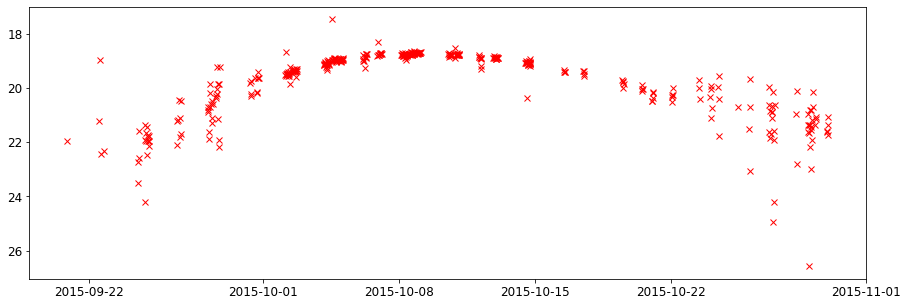

In [8]:
SN_flux = fluxes[-1,:]
ref_mags = [16.32, 17.16, 15.61]
SN_mags = np.empty((len(stars) - 1, SN_flux.size))

for i in range(fluxes.shape[0] - 1):
#     print(2.512*np.log10(fluxes[i,:]/SN_flux)+ ref_mags[i])
    print("Hello", fluxes.shape[0] - 1)
    SN_mags[i,:] = 2.512*np.log10(fluxes[i,:]/SN_flux) + ref_mags[i]
    print(SN_mags[i,-200:])
    
    
    
mean_SN_mags = np.mean(SN_mags, axis = 0)



plt.figure(figsize = (15,5))
# for i in range(SN_mags.shape[0]):
plt.plot(file_times[_filter], mean_SN_mags[_filter], 'x', color ='r')
# plt.plot(file_times,mean_SN_mags, 'x', color ='k')
np.save("observation_times", file_times[_filter])
np.save("light_curve", mean_SN_mags[_filter])
# plt.yscale('log')
# plt.ylim(1e3, 2e5)
plt.gca().invert_yaxis()
plt.show()  